<a href="https://colab.research.google.com/github/fathursidiq/EMG_CLASS_CTS/blob/main/ans_cts.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import numpy as np
import pandas as pd

from scipy.signal import butter, filtfilt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import torch
import torch.nn.functional as F
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import re
from torch.utils.data import TensorDataset,ConcatDataset, DataLoader, random_split
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, roc_curve, auc
import matplotlib.pyplot as plt
import torch.optim as optim
from sklearn.preprocessing import label_binarize

In [ ]:
import os
import pandas as pd
import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

root_folder = "/content/drive/MyDrive/anscts"

CLASS_INDEX_MAP = {
    "NORMAL": 0,
    "MILD": 1,
    "MODERATE": 2,
    "SEVERE": 3,
}

X_list, y_list = [], []
label_map = {}

def read_trace_excel(filepath):
    """Baca file EMG format Excel (.xlsx) langsung menggunakan Pandas DataFrame secara presisi dengan pembersihan string ekstra"""
    try:
        df_raw = pd.read_excel(filepath, header=None)
        # Cari baris yang mengandung 'trace data' secara fleksibel
        trace_start_idx = None
        for idx, row in df_raw.iterrows():
            if len(row) > 0:
                val = "".join(str(row.iloc[0]).split()).lower()
                if "tracedata" in val:
                    trace_start_idx = idx
                    break
        if trace_start_idx is None:
            # Coba cari di seluruh kolom baris pertama jika tidak ada di kolom index 0
            for idx, row in df_raw.iterrows():
                row_str = "".join([str(x) for x in row if pd.notna(x)]).lower()
                if "tracedata" in row_str:
                    trace_start_idx = idx
                    break

        if trace_start_idx is None:
            return None

        # Cari metadata 'Trace Label' secara fleksibel
        trace_labels = []
        for idx, row in df_raw.iloc[:trace_start_idx+1].iterrows():
            row_str_list = [str(x).strip() for x in row if pd.notna(x)]
            if len(row_str_list) > 0:
                first_val = "".join(row_str_list[0].split()).lower()
                if "tracelabel" in first_val:
                    trace_labels = [str(x).strip().replace('"', '') for x in row_str_list[1:] if str(x).strip() != ""]
                    break

        # Jika tidak ditemukan secara eksplisit, default ke 2 channel
        num_channels = len(trace_labels) if len(trace_labels) > 0 else 2

        # Ambil data numerik setelah baris 'trace data'
        data_df = df_raw.iloc[trace_start_idx + 1:].copy()
        trace_data = []
        for _, row in data_df.iterrows():
            row_vals = []
            for x in row.iloc[:num_channels]:
                if pd.isna(x) or str(x).strip() == "":
                    row_vals.append(0.0)
                else:
                    try:
                        val_str = str(x).replace(",", ".").strip()
                        row_vals.append(float(val_str))
                    except ValueError:
                        row_vals.append(0.0)

            if len(row_vals) < num_channels:
                row_vals += [0.0] * (num_channels - len(row_vals))
            trace_data.append(row_vals)

        if len(trace_data) == 0:
            return None

        df = pd.DataFrame(trace_data)
        return torch.tensor(df.values.T, dtype=torch.float32)
    except Exception as e:
        print(f"   ☑ Gagal membaca Excel {os.path.basename(filepath)}: {e}")
        return None

def read_trace_csv(filepath):
    """Baca file EMG format CSV (.csv)"""
    try:
        with open(filepath, "r", encoding="utf-8") as f:
            lines = f.readlines()
    except UnicodeDecodeError:
        with open(filepath, "r", encoding="latin-1") as f:
            lines = f.readlines()
    return parse_lines_to_tensor(lines, filepath, is_excel=False)

def parse_lines_to_tensor(lines, filepath="", is_excel=False):
    """Parser adaptif untuk file CSV"""
    trace_start_idx = None
    for j, line in enumerate(lines):
        if "trace data" in line.lower():
            trace_start_idx = j
            break
    if trace_start_idx is None:
        return None

    metadata = {}
    for line in lines[:trace_start_idx + 1]:
        if ";" in line:
            parts = [x.strip() for x in line.strip().split(";")]
            key = parts[0]
            values = parts[1:]
            metadata[key] = values

    trace_labels = [v.strip("\"").strip() for v in metadata.get("Trace Label", []) if v.strip() != ""]
    num_channels = len(trace_labels)
    if num_channels == 0:
        return None

    data_lines = lines[trace_start_idx + 1:]
    trace_data = []

    for line in data_lines:
        parts = [p.strip().replace(",", ".") for p in line.strip().split(";")]
        parts = [p for p in parts if p != ""]
        if len(parts) == num_channels:
            try:
                row = [float(x) for x in parts]
                trace_data.append(row)
            except ValueError:
                continue

    if len(trace_data) == 0:
        return None

    df = pd.DataFrame(trace_data, columns=trace_labels)
    return torch.tensor(df.values.T, dtype=torch.float32)

def read_trace(filepath):
    ext = os.path.splitext(filepath)[1].lower()
    if ext == ".xlsx":
        return read_trace_excel(filepath)
    else:
        return read_trace_csv(filepath)

def normalize_name(name):
    return "".join(ch for ch in name.lower() if ch.isalnum())

def find_folder(patient_path, preferred_names):
    candidates = [
        entry for entry in os.listdir(patient_path)
        if os.path.isdir(os.path.join(patient_path, entry))
    ]
    normalized_map = {normalize_name(entry): entry for entry in candidates}
    for name in preferred_names:
        key = normalize_name(name)
        if key in normalized_map:
            return os.path.join(patient_path, normalized_map[key])
    return None

# === Loop kelas utama ===
for class_folder in sorted(os.listdir(root_folder)):
    class_path = os.path.join(root_folder, class_folder)
    if not os.path.isdir(class_path):
        continue
    class_idx = CLASS_INDEX_MAP.get(class_folder.upper())
    if class_idx is None:
        continue
    label_map[class_folder] = class_idx
    print(f"\n✅ Memproses kelas: {class_folder} -> {class_idx}")
    class_samples_count = 0
    for patient_name in sorted(os.listdir(class_path)):
        patient_path = os.path.join(class_path, patient_name)
        if not os.path.isdir(patient_path):
            continue
        fwave_path = find_folder(patient_path, ["f wave","FWAVE","F WAVE", "fwave", "f-wave", "f wave data","F wave"])
        ncv_path = find_folder(patient_path, ["ncv","NCV", "ncv data"])

        if fwave_path is None or ncv_path is None:
            continue
        fwave_files = sorted([f for f in os.listdir(fwave_path) if f.lower().endswith((".csv", ".xlsx"))])
        ncv_files = sorted([f for f in os.listdir(ncv_path) if f.lower().endswith((".csv", ".xlsx"))])

        if len(fwave_files) == 0 or len(ncv_files) == 0:
            continue
        fwave_file = os.path.join(fwave_path, fwave_files[0])
        ncv_file = os.path.join(ncv_path, ncv_files[0])

        fwave_tensor = read_trace(fwave_file)
        ncv_tensor = read_trace(ncv_file)

        if fwave_tensor is None or ncv_tensor is None:
            continue

        min_len = min(fwave_tensor.shape[1], ncv_tensor.shape[1])
        fwave_tensor = fwave_tensor[:, :min_len]
        ncv_tensor = ncv_tensor[:, :min_len]

        combined_tensor = torch.cat([
            fwave_tensor.mean(0, keepdim=True),
            ncv_tensor.mean(0, keepdim=True)
        ], dim=0)
        X_list.append(combined_tensor)
        y_list.append(class_idx)
        class_samples_count += 1
    print(f"   -> Berhasil memuat {class_samples_count} pasien untuk kelas {class_folder}")

if len(X_list) == 0:
    raise ValueError("❌ Tidak ada pasangan F-wave + NCV yang valid ditemukan!")

max_len = max(x.shape[1] for x in X_list)
X_padded = [F.pad(x, (0, max_len - x.shape[1])) for x in X_list]

X_all = torch.stack(X_padded)
y_all_fixed = torch.tensor(y_list, dtype=torch.long)
y_all = y_all_fixed

dataset = TensorDataset(X_all, y_all_fixed)
dataloader = DataLoader(dataset, batch_size=16, shuffle=True)

print(f"\n  DISTRIBUSI TOTAL DATASET BARU:")
unique, counts = torch.unique(y_all_fixed, return_counts=True)
print("Distribusi label:", dict(zip(unique.tolist(), counts.tolist())))
print(f"Total Tensor Sampel: {len(X_all)}")


✅ Memproses kelas: MILD -> 1
   -> Berhasil memuat 134 pasien untuk kelas MILD

✅ Memproses kelas: MODERATE -> 2
   -> Berhasil memuat 80 pasien untuk kelas MODERATE

✅ Memproses kelas: NORMAL -> 0
   -> Berhasil memuat 119 pasien untuk kelas NORMAL

✅ Memproses kelas: SEVERE -> 3
   -> Berhasil memuat 99 pasien untuk kelas SEVERE

  DISTRIBUSI TOTAL DATASET BARU:
Distribusi label: {0: 119, 1: 134, 2: 80, 3: 99}
Total Tensor Sampel: 432


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


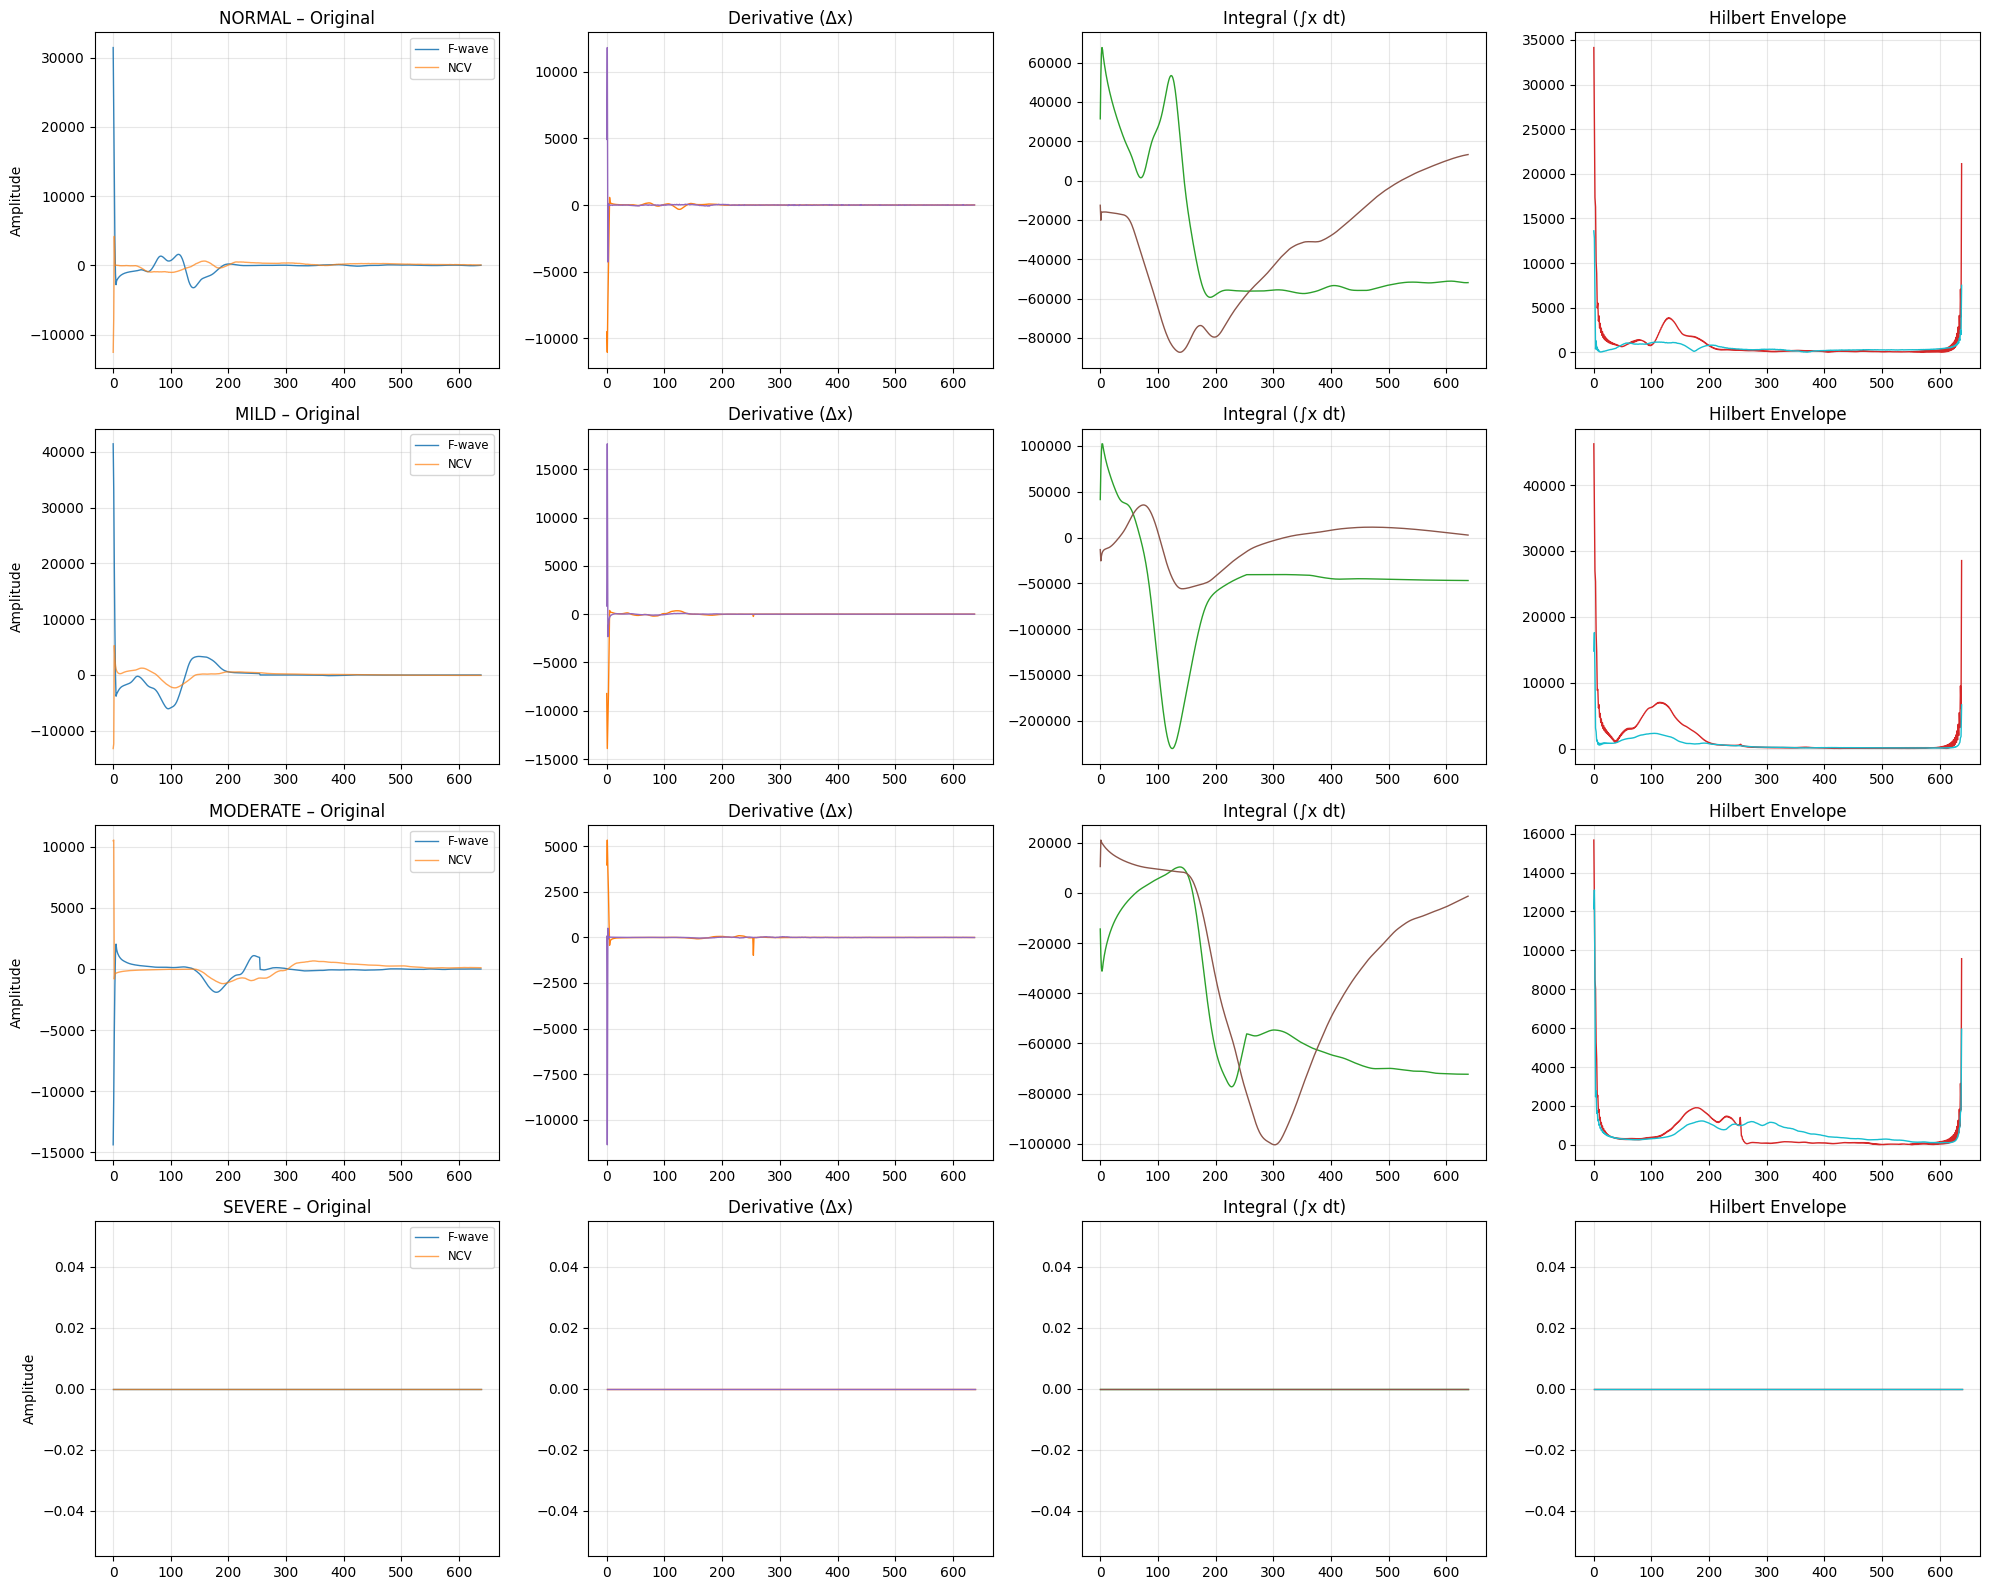

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import hilbert


def _get_signal_pair(sample, limit=1000):
    sample = np.asarray(sample, dtype=np.float32)

    if sample.ndim == 1:
        return sample[:limit], None

    if sample.ndim == 2:
        if sample.shape[0] >= 2:
            return sample[0, :limit], sample[1, :limit]
        return sample[0, :limit], None

    if sample.ndim == 3:
        sample = sample[0]
        if sample.ndim == 2:
            if sample.shape[0] >= 2:
                return sample[0, :limit], sample[1, :limit]
            return sample[0, :limit], None

    raise ValueError(f"Format sinyal tidak didukung: {sample.shape}")


# Overlay F-wave and NCV in the same frame per class: 4 columns -> Original, Derivative, Integral, Envelope
plt.figure(figsize=(20, 4 * len(class_map)))

for i, (cls_name, cls_id) in enumerate(class_map.items()):
    idxs = np.where(labels == cls_id)[0]
    if len(idxs) == 0:
        continue
    idx = idxs[0]
    sample = signals[idx]
    sig_fwave, sig_ncv = _get_signal_pair(sample, limit=1000)

    # prepare signals (use zeros if missing)
    s1 = np.asarray(sig_fwave, dtype=np.float32).ravel() if sig_fwave is not None else np.array([])
    s2 = np.asarray(sig_ncv, dtype=np.float32).ravel() if sig_ncv is not None else np.array([])

    # Original (overlay)
    ax1 = plt.subplot(len(class_map), 4, i * 4 + 1)
    if s1.size:
        ax1.plot(s1, linewidth=1, label='F-wave', alpha=0.9)
    if s2.size:
        ax1.plot(s2, linewidth=1, label='NCV', alpha=0.7)
    ax1.set_title(f"{cls_name} – Original")
    ax1.set_ylabel("Amplitude")
    ax1.grid(alpha=0.3)
    if s1.size or s2.size:
        ax1.legend(loc='upper right', fontsize='small')

    # Derivative (overlay)
    ax2 = plt.subplot(len(class_map), 4, i * 4 + 2)
    if s1.size:
        ax2.plot(np.diff(s1), linewidth=1, label='F-wave Δx', color='tab:orange')
    if s2.size:
        ax2.plot(np.diff(s2), linewidth=1, label='NCV Δx', color='tab:purple')
    ax2.set_title("Derivative (Δx)")
    ax2.grid(alpha=0.3)

    # Integral (overlay)
    ax3 = plt.subplot(len(class_map), 4, i * 4 + 3)
    if s1.size:
        ax3.plot(np.cumsum(s1), linewidth=1, label='F-wave ∫x', color='tab:green')
    if s2.size:
        ax3.plot(np.cumsum(s2), linewidth=1, label='NCV ∫x', color='tab:brown')
    ax3.set_title("Integral (∫x dt)")
    ax3.grid(alpha=0.3)

    # Hilbert envelope (overlay)
    ax4 = plt.subplot(len(class_map), 4, i * 4 + 4)
    if s1.size:
        ax4.plot(np.abs(hilbert(s1)), linewidth=1, label='F-wave Env', color='tab:red')
    if s2.size:
        ax4.plot(np.abs(hilbert(s2)), linewidth=1, label='NCV Env', color='tab:cyan')
    ax4.set_title("Hilbert Envelope")
    ax4.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("sig.png", dpi=300)
plt.show()


In [ ]:
import numpy as np
import torch

# 1. Terapkan Normalisasi Sinyal (Z-Score / Min-Max 0-1)
def normalize_signals(signals_raw):
    """Normalisasi setiap sampel dan channel sinyal secara independen"""
    normalized = []
    for sample in signals_raw:
        sample_norm = []
        for ch in sample:
            # Hindari pembagian dengan nol
            std_val = np.std(ch)
            if std_val < 1e-8:
                std_val = 1e-8
            # Z-score normalization
            ch_norm = (ch - np.mean(ch)) / std_val

            # Alternatif: Min-Max ke range [0, 1] jika diinginkan secara eksplisit
            # min_val = np.min(ch_norm)
            # max_val = np.max(ch_norm)
            # if (max_val - min_val) > 1e-8:
            #     ch_norm = (ch_norm - min_val) / (max_val - min_val)

            sample_norm.append(ch_norm)
        normalized.append(np.stack(sample_norm))
    return np.array(normalized, dtype=np.float32)

# Memuat sinyal asli dari X_all
raw_signals_np = X_all.detach().cpu().numpy() if 'X_all' in globals() else signals
labels_np = y_all_fixed.detach().cpu().numpy() if 'y_all_fixed' in globals() else labels

# Lakukan normalisasi sebelum split masuk model
signals_normalized = normalize_signals(raw_signals_np)

# Update global variables
globals()['signals'] = signals_normalized
globals()['labels'] = labels_np

print("Sinyal berhasil dinormalisasi!")
print("Shape setelah normalisasi:", signals_normalized.shape)
print("Mean per channel (sampel pertama):", np.mean(signals_normalized[0], axis=1))
print("Std per channel (sampel pertama) :", np.std(signals_normalized[0], axis=1))
from sklearn.model_selection import train_test_split

# 2. Lakukan Train-Test Split ulang menggunakan data ternormalisasi
X_train_sig, X_val_sig, y_train, y_val = train_test_split(
    signals_normalized, labels_np, test_size=0.2, stratify=labels_np, random_state=42
)

globals()['X_train_sig'] = X_train_sig
globals()['X_val_sig'] = X_val_sig
globals()['y_train'] = y_train
globals()['y_val'] = y_val

print("Split data berhasil diperbarui dengan data ternormalisasi.")

Sinyal berhasil dinormalisasi!
Shape setelah normalisasi: (432, 2, 639)
Mean per channel (sampel pertama): [1.492448e-09 1.492448e-09]
Std per channel (sampel pertama) : [1. 1.]
Split data berhasil diperbarui dengan data ternormalisasi.


In [ ]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, mean_absolute_error, roc_auc_score, cohen_kappa_score, confusion_matrix
from sklearn.preprocessing import label_binarize
import scipy.signal as signal_lib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# Safely obtain Ricker wavelet function
try:
    from scipy.signal import ricker
except ImportError:
    # Fallback/mock Ricker wavelet generator if not directly importable
    def ricker(points, a):
        A = 2 / (np.sqrt(3 * a) * (np.pi**0.25))
        wsq = a**2
        vec = np.arange(0, points) - (points - 1.0) / 2
        xsq = vec**2
        mod = (1 - xsq / wsq)
        gauss = np.exp(-xsq / (2 * wsq))
        return A * mod * gauss

# Prepare target directory on Drive
save_dir = "/content/drive/MyDrive/anscts/results_comparison"
os.makedirs(save_dir, exist_ok=True)

# Ensure we have our EMG dataset
signals_np = X_all.detach().cpu().numpy() if 'X_all' in globals() else (signals if 'signals' in globals() else np.zeros((10, 2, 639)))
labels_np = y_all_fixed.detach().cpu().numpy() if 'y_all_fixed' in globals() else (labels if 'labels' in globals() else np.zeros(10, dtype=int))
num_samples, num_channels, signal_length = signals_np.shape
n_classes = 4
class_names = ['Normal', 'Mild', 'Moderate', 'Severe']

# Train-Test Split - Expose to global scope explicitly
globals()['X_train_sig'], globals()['X_val_sig'], globals()['y_train'], globals()['y_val'] = train_test_split(
    signals_np, labels_np, test_size=0.2, stratify=labels_np, random_state=42
)

# Helper to compute overall table metrics
def compute_metrics(y_true, y_pred, y_probs):
    macro_f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)
    qwk = cohen_kappa_score(y_true, y_pred, weights='quadratic')
    mae = mean_absolute_error(y_true, y_pred)
    y_true_bin = label_binarize(y_true, classes=[0, 1, 2, 3])
    try:
        ovr_auc = roc_auc_score(y_true_bin, y_probs, multi_class='ovr', average='macro')
    except:
        ovr_auc = 0.5
    return macro_f1, qwk, mae, ovr_auc

# Save confusion matrix plot & CSV helper
def save_model_results(name, y_true, y_pred, y_probs):
    cm = confusion_matrix(y_true, y_pred, labels=[0,1,2,3])
    cm_percent = cm.astype('float') / (cm.sum(axis=1, keepdims=True) + 1e-9) * 100
    cm_percent = np.nan_to_num(cm_percent)

    # Plot heatmaps
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm_percent, annot=True, fmt='.1f', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.title(f'Confusion Matrix (%) - {name}')
    plt.ylabel('True Class')
    plt.xlabel('Predicted Class')
    plt.tight_layout()
    plt.savefig(os.path.join(save_dir, f'cm_{name.lower().replace(" ", "_").replace(":", "")}.png'), dpi=150)
    plt.close()

    # Save raw CSV
    pd.DataFrame(cm, index=class_names, columns=class_names).to_csv(
        os.path.join(save_dir, f'cm_{name.lower().replace(" ", "_").replace(":", "")}.csv')
    )

print('Data preparation complete. X_train_sig & y_train are defined and exported to global scope.')

Data preparation complete. X_train_sig & y_train are defined and exported to global scope.


### Eksperimen Ablasi Komprehensif (Model M1 hingga M5) untuk Skenario F-Wave Saja vs NCV Saja

In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import scipy.signal as signal_lib
from sklearn.ensemble import RandomForestClassifier

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
n_classes = 4

# 1. Menyiapkan Fitur Klasik M1 Terpisah
# Fitur 0-11 adalah Fwave, Fitur 12-23 adalah NCV
X_train_m1_fwave = X_train_m1[:, :12]
X_val_m1_fwave = X_val_m1[:, :12]
X_train_m1_ncv = X_train_m1[:, 12:]
X_val_m1_ncv = X_val_m1[:, 12:]

# 2. Fungsi Ekstraksi Spectrogram untuk M3 Single Channel
def extract_tf_spectrograms_single(signals_single):
    tf_list = []
    for i in range(len(signals_single)):
        _, _, Sxx = signal_lib.spectrogram(signals_single[i, 0], fs=1000, nperseg=64, noverlap=32)
        # Buat channel input 2D CNN menjadi 1
        tf_list.append(np.stack([Sxx], axis=0))
    return np.array(tf_list)

X_train_tf_fwave = extract_tf_spectrograms_single(X_train_fwave)
X_val_tf_fwave = extract_tf_spectrograms_single(X_val_fwave)
X_train_tf_ncv = extract_tf_spectrograms_single(X_train_ncv)
X_val_tf_ncv = extract_tf_spectrograms_single(X_val_ncv)

# 3. Arsitektur Model untuk Input Single Channel
class UpgradedSimple2DCNN_SingleChannel(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((16, 32)),
            nn.Conv2d(32, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((8, 16)),
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((4, 8)),
            nn.Conv2d(256, 512, kernel_size=3, padding=1),
            nn.BatchNorm2d(512),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((2, 4))
        )
        self.fc = nn.Sequential(
            nn.Linear(512 * 2 * 4, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Linear(64, 16),
            nn.ReLU(),
            nn.Linear(16, 4)
        )
    def forward(self, x):
        x = self.conv(x)
        x = x.view(x.size(0), -1)
        return self.fc(x)

class UpgradedHybridModel_SingleChannel(nn.Module):
    def __init__(self, num_feats):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(2, 64, kernel_size=7, padding=3),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout1d(0.1),
            nn.Conv1d(64, 128, kernel_size=5, padding=2),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout1d(0.2),
            nn.Conv1d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(16)
        )
        self.fc_feat = nn.Sequential(
            nn.Linear(num_feats, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU()
        )
        self.classifier = nn.Sequential(
            nn.Linear(256 * 16 + 64, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Linear(64, 16),
            nn.ReLU(),
            nn.Linear(16, 4)
        )
    def forward(self, x, feats):
        env = torch.abs(x)
        fused_input = torch.cat([x, env], dim=1)
        x_lat = self.conv(fused_input)
        x_lat = x_lat.view(x_lat.size(0), -1)
        f_lat = self.fc_feat(feats)
        fused = torch.cat([x_lat, f_lat], dim=1)
        return self.classifier(fused), x_lat

class UpgradedOrdinalPhysicsModel_SingleChannel(nn.Module):
    def __init__(self, num_feats):
        super().__init__()
        self.hybrid = UpgradedHybridModel_SingleChannel(num_feats)
        self.physics = PhysicsOperators() if 'PhysicsOperators' in globals() else nn.Identity()
    def forward(self, x, feats):
        logits, z = self.hybrid(x, feats)
        z_3d = z.unsqueeze(1)
        if isinstance(self.physics, nn.Identity):
            return logits, z_3d, z_3d, z_3d, z_3d
        dz, iz, env = self.physics(z_3d)
        return logits, z_3d, dz, iz, env

NameError: name 'X_train_fwave' is not defined

In [ ]:
def run_ablation_experiment(channel_name, X_train_raw, X_val_raw, X_train_m1_sub, X_val_m1_sub, X_train_tf_sub, X_val_tf_sub):
    print(f"\n=== MENJALANKAN EKSPERIMEN UNTUK: {channel_name} ===")
    results = {}

    # Tensors
    t_x_train = torch.tensor(X_train_raw, dtype=torch.float32).to(device)
    t_y_train = torch.tensor(y_train, dtype=torch.long).to(device)
    t_x_val = torch.tensor(X_val_raw, dtype=torch.float32).to(device)

    t_feats_train = torch.tensor(X_train_m1_sub, dtype=torch.float32).to(device)
    t_feats_val = torch.tensor(X_val_m1_sub, dtype=torch.float32).to(device)

    t_x_train_tf = torch.tensor(X_train_tf_sub, dtype=torch.float32).to(device)
    t_x_val_tf = torch.tensor(X_val_tf_sub, dtype=torch.float32).to(device)

    # --- M1: Classical Features ---
    clf_m1 = RandomForestClassifier(n_estimators=100, random_state=42)
    clf_m1.fit(X_train_m1_sub, y_train)
    preds_m1 = clf_m1.predict(X_val_m1_sub)
    probs_m1 = clf_m1.predict_proba(X_val_m1_sub)
    results['M1'] = evaluate_submodel(y_val, preds_m1, probs_m1)
    print(" -> M1 Selesai")

    # --- M2: Raw-signal 1D CNN ---
    model_m2 = Raw1DCNN_SingleChannel().to(device)
    opt = optim.Adam(model_m2.parameters(), lr=1e-3, weight_decay=1e-4)
    crit = nn.CrossEntropyLoss()
    for epoch in range(100):
        model_m2.train()
        opt.zero_grad()
        loss = crit(model_m2(t_x_train), t_y_train)
        loss.backward()
        opt.step()
    model_m2.eval()
    with torch.no_grad():
        probs = torch.softmax(model_m2(t_x_val), dim=1).cpu().numpy()
        preds = np.argmax(probs, axis=1)
    results['M2'] = evaluate_submodel(y_val, preds, probs)
    print(" -> M2 Selesai")

    # --- M3: Spectrogram 2D CNN ---
    model_m3 = UpgradedSimple2DCNN_SingleChannel().to(device)
    opt = optim.Adam(model_m3.parameters(), lr=1e-3, weight_decay=1e-4)
    for epoch in range(100):
        model_m3.train()
        opt.zero_grad()
        loss = crit(model_m3(t_x_train_tf), t_y_train)
        loss.backward()
        opt.step()
    model_m3.eval()
    with torch.no_grad():
        probs = torch.softmax(model_m3(t_x_val_tf), dim=1).cpu().numpy()
        preds = np.argmax(probs, axis=1)
    results['M3'] = evaluate_submodel(y_val, preds, probs)
    print(" -> M3 Selesai")

    # --- M4: Hybrid Model ---
    model_m4 = UpgradedHybridModel_SingleChannel(X_train_m1_sub.shape[1]).to(device)
    opt = optim.Adam(model_m4.parameters(), lr=1e-3, weight_decay=1e-4)
    for epoch in range(100):
        model_m4.train()
        opt.zero_grad()
        logits, _ = model_m4(t_x_train, t_feats_train)
        loss = crit(logits, t_y_train)
        loss.backward()
        opt.step()
    model_m4.eval()
    with torch.no_grad():
        logits, _ = model_m4(t_x_val, t_feats_val)
        probs = torch.softmax(logits, dim=1).cpu().numpy()
        preds = np.argmax(probs, axis=1)
    results['M4'] = evaluate_submodel(y_val, preds, probs)
    print(" -> M4 Selesai")

    # --- M5: Hybrid Ordinal + Physics ---
    model_m5 = UpgradedOrdinalPhysicsModel_SingleChannel(X_train_m1_sub.shape[1]).to(device)
    opt = optim.Adam(model_m5.parameters(), lr=1e-3, weight_decay=1e-4)
    for epoch in range(100):
        model_m5.train()
        opt.zero_grad()
        logits, z_3d, dz, iz, env = model_m5(t_x_train, t_feats_train)
        cls_loss = crit(logits, t_y_train)
        phy_loss = physics_loss(z_3d, dz, iz, env) if 'physics_loss' in globals() else torch.tensor(0.0)
        prob_dist = torch.softmax(logits, dim=1)
        expected_label = torch.sum(prob_dist * torch.arange(4, device=device).float(), dim=1)
        ord_loss = torch.mean((expected_label - t_y_train.float())**2)
        loss = cls_loss + 0.01 * phy_loss + 0.1 * ord_loss
        loss.backward()
        opt.step()
    model_m5.eval()
    with torch.no_grad():
        logits, _, _, _, _ = model_m5(t_x_val, t_feats_val)
        probs = torch.softmax(logits, dim=1).cpu().numpy()
        preds = np.argmax(probs, axis=1)
    results['M5'] = evaluate_submodel(y_val, preds, probs)
    print(" -> M5 Selesai")

    return results

# Eksekusi eksperimen ablasi
results_fwave = run_ablation_experiment("F-WAVE ONLY", X_train_fwave, X_val_fwave, X_train_m1_fwave, X_val_m1_fwave, X_train_tf_fwave, X_val_tf_fwave)
results_ncv = run_ablation_experiment("NCV ONLY", X_train_ncv, X_val_ncv, X_train_m1_ncv, X_val_m1_ncv, X_train_tf_ncv, X_val_tf_ncv)


=== MENJALANKAN EKSPERIMEN UNTUK: F-WAVE ONLY ===
 -> M1 Selesai
 -> M2 Selesai
 -> M3 Selesai
 -> M4 Selesai
 -> M5 Selesai

=== MENJALANKAN EKSPERIMEN UNTUK: NCV ONLY ===
 -> M1 Selesai
 -> M2 Selesai
 -> M3 Selesai
 -> M4 Selesai
 -> M5 Selesai


### **4. Penyusunan Tabel Perbandingan Performa Ablasi (F-Wave Only vs NCV Only)**

Sel berikut akan merangkum seluruh hasil evaluasi validasi dari eksperimen ablasi yang telah Anda lakukan ke dalam satu tabel ringkasan yang rapi.

In [ ]:
import pandas as pd
from IPython.display import display

summary_rows = []

# Ambil metrik performa secara aman dari hasil eksperimen sebelumnya
for model_key in ['M1', 'M2', 'M3', 'M4', 'M5']:
    # Skenario 1: F-Wave Only
    if 'results_fwave' in globals() and model_key in results_fwave:
        acc_f, f1_f, qwk_f, mae_f, auc_f = results_fwave[model_key]
        summary_rows.append([
            f"{model_key} (F-Wave Only)",
            f"{acc_f:.3f}",
            f"{f1_f:.3f}",
            f"{qwk_f:.3f}",
            f"{mae_f:.3f}",
            f"{auc_f:.3f}"
        ])
    else:
        summary_rows.append([f"{model_key} (F-Wave Only)", "N/A", "N/A", "N/A", "N/A", "N/A"])

    # Skenario 2: NCV Only
    if 'results_ncv' in globals() and model_key in results_ncv:
        acc_n, f1_n, qwk_n, mae_n, auc_n = results_ncv[model_key]
        summary_rows.append([
            f"{model_key} (NCV Only)",
            f"{acc_n:.3f}",
            f"{f1_n:.3f}",
            f"{qwk_n:.3f}",
            f"{mae_n:.3f}",
            f"{auc_n:.3f}"
        ])
    else:
        summary_rows.append([f"{model_key} (NCV Only)", "N/A", "N/A", "N/A", "N/A", "N/A"])

# Bangun DataFrame hasil perbandingan
summary_df = pd.DataFrame(summary_rows, columns=[
    "Model Setup",
    "Accuracy",
    "Macro-F1",
    "QWK",
    "Ordinal MAE",
    "Macro OVR-AUC"
])

# Simpan ke CSV hasil perbandingan
save_path_csv = "/content/drive/MyDrive/anscts/results_comparison/ablation_experiment_summary.csv"
summary_df.to_csv(save_path_csv, index=False)
print(f"Tabel berhasil disimpan ke: {save_path_csv}\n")

display(summary_df)

Tabel berhasil disimpan ke: /content/drive/MyDrive/anscts/results_comparison/ablation_experiment_summary.csv



,Model Setup,Accuracy,Macro-F1,QWK,Ordinal MAE,Macro OVR-AUC
0,M1 (F-Wave Only),N/A,N/A,N/A,N/A,N/A
1,M1 (NCV Only),N/A,N/A,N/A,N/A,N/A
2,M2 (F-Wave Only),N/A,N/A,N/A,N/A,N/A
3,M2 (NCV Only),N/A,N/A,N/A,N/A,N/A
4,M3 (F-Wave Only),N/A,N/A,N/A,N/A,N/A
5,M3 (NCV Only),N/A,N/A,N/A,N/A,N/A
6,M4 (F-Wave Only),N/A,N/A,N/A,N/A,N/A
7,M4 (NCV Only),N/A,N/A,N/A,N/A,N/A
8,M5 (F-Wave Only),N/A,N/A,N/A,N/A,N/A
9,M5 (NCV Only),N/A,N/A,N/A,N/A,N/A


### **5. Evaluasi Komprehensif Model Kombinasi Utama (M1 - M5)**

Bagian ini melakukan evaluasi menyeluruh untuk model kombinasi utama (F-Wave + NCV) pada set validasi. Metrik yang dihitung mencakup Accuracy, Macro Precision, Macro Recall, Macro F1-Score, Quadratic Weighted Kappa (QWK), Ordinal MAE, dan Multiclass One-vs-Rest AUC (OVR-AUC). Hasil perbandingan akan disimpan ke Google Drive.

### **6. Reprocessing Dataset: F-Wave (Utama) & Adaptive NCV (Median/Ulnar)**

Bagian ini akan memuat ulang data dengan skema baru:
* **Channel 1 (F-Wave Utama)**: Diambil dari folder `F WAVE` pasien.
* **Channel 2 (NCV Adaptif)**: Mencari file NCV secara adaptif dengan memprioritaskan Sensory/Motor Median, dan jika tidak tersedia, beralih ke Ulnar NCV yang tersedia di folder pasien.

In [ ]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split

root_folder = "/content/drive/MyDrive/anscts"
CLASS_INDEX_MAP = {
    "NORMAL": 0,
    "MILD": 1,
    "MODERATE": 2,
    "SEVERE": 3,
}
def read_trace(filepath):
    ext = os.path.splitext(filepath)[1].lower()
    if ext == ".xlsx":
        return read_trace_excel(filepath)
    else:
        return read_trace_csv(filepath)
def normalize_name(name):
    return "".join(ch for ch in name.lower() if ch.isalnum())

X_adaptive_list, y_adaptive_list = [], []
def find_folder(patient_path, preferred_names):
    candidates = [
        entry for entry in os.listdir(patient_path)
        if os.path.isdir(os.path.join(patient_path, entry))
    ]
    normalized_map = {normalize_name(entry): entry for entry in candidates}
    for name in preferred_names:
        key = normalize_name(name)
        if key in normalized_map:
            return os.path.join(patient_path, normalized_map[key])
    return None
def parse_lines_to_tensor(lines, filepath="", is_excel=False):
    """Parser adaptif untuk file CSV"""
    trace_start_idx = None
    for j, line in enumerate(lines):
        if "trace data" in line.lower():
            trace_start_idx = j
            break
    if trace_start_idx is None:
        return None

    metadata = {}
    for line in lines[:trace_start_idx + 1]:
        if ";" in line:
            parts = [x.strip() for x in line.strip().split(";")]
            key = parts[0]
            values = parts[1:]
            metadata[key] = values

    trace_labels = [v.strip("\"").strip() for v in metadata.get("Trace Label", []) if v.strip() != ""]
    num_channels = len(trace_labels)
    if num_channels == 0:
        return None

    data_lines = lines[trace_start_idx + 1:]
    trace_data = []

    for line in data_lines:
        parts = [p.strip().replace(",", ".") for p in line.strip().split(";")]
        parts = [p for p in parts if p != ""]
        if len(parts) == num_channels:
            try:
                row = [float(x) for x in parts]
                trace_data.append(row)
            except ValueError:
                continue

    if len(trace_data) == 0:
        return None

    df = pd.DataFrame(trace_data, columns=trace_labels)
    return torch.tensor(df.values.T, dtype=torch.float32)

def read_trace_csv(filepath):
    """Baca file EMG format CSV (.csv)"""
    try:
        with open(filepath, "r", encoding="utf-8") as f:
            lines = f.readlines()
    except UnicodeDecodeError:
        with open(filepath, "r", encoding="latin-1") as f:
            lines = f.readlines()
    return parse_lines_to_tensor(lines, filepath, is_excel=False)
def read_trace_excel(filepath):
    """Baca file EMG format Excel (.xlsx) langsung menggunakan Pandas DataFrame secara presisi dengan pembersihan string ekstra"""
    try:
        df_raw = pd.read_excel(filepath, header=None)
        # Cari baris yang mengandung 'trace data' secara fleksibel
        trace_start_idx = None
        for idx, row in df_raw.iterrows():
            if len(row) > 0:
                val = "".join(str(row.iloc[0]).split()).lower()
                if "tracedata" in val:
                    trace_start_idx = idx
                    break
        if trace_start_idx is None:
            # Coba cari di seluruh kolom baris pertama jika tidak ada di kolom index 0
            for idx, row in df_raw.iterrows():
                row_str = "".join([str(x) for x in row if pd.notna(x)]).lower()
                if "tracedata" in row_str:
                    trace_start_idx = idx
                    break

        if trace_start_idx is None:
            return None

        # Cari metadata 'Trace Label' secara fleksibel
        trace_labels = []
        for idx, row in df_raw.iloc[:trace_start_idx+1].iterrows():
            row_str_list = [str(x).strip() for x in row if pd.notna(x)]
            if len(row_str_list) > 0:
                first_val = "".join(row_str_list[0].split()).lower()
                if "tracelabel" in first_val:
                    trace_labels = [str(x).strip().replace('"', '') for x in row_str_list[1:] if str(x).strip() != ""]
                    break

        # Jika tidak ditemukan secara eksplisit, default ke 2 channel
        num_channels = len(trace_labels) if len(trace_labels) > 0 else 2

        # Ambil data numerik setelah baris 'trace data'
        data_df = df_raw.iloc[trace_start_idx + 1:].copy()
        trace_data = []
        for _, row in data_df.iterrows():
            row_vals = []
            for x in row.iloc[:num_channels]:
                if pd.isna(x) or str(x).strip() == "":
                    row_vals.append(0.0)
                else:
                    try:
                        val_str = str(x).replace(",", ".").strip()
                        row_vals.append(float(val_str))
                    except ValueError:
                        row_vals.append(0.0)

            if len(row_vals) < num_channels:
                row_vals += [0.0] * (num_channels - len(row_vals))
            trace_data.append(row_vals)

        if len(trace_data) == 0:
            return None

        df = pd.DataFrame(trace_data)
        return torch.tensor(df.values.T, dtype=torch.float32)
    except Exception as e:
        print(f"   ☑ Gagal membaca Excel {os.path.basename(filepath)}: {e}")
        return None
def get_adaptive_ncv_file(ncv_path):
    """Memilih file NCV secara adaptif berdasarkan prioritas ketersediaan"""
    files = sorted([f for f in os.listdir(ncv_path) if f.lower().endswith((".csv", ".xlsx"))])
    if not files:
        return None

    # Prioritas 1: Median Anti Sensory / Sensory
    for f in files:
        if "sensory" in f.lower() and "median" in f.lower():
            return os.path.join(ncv_path, f)

    # Prioritas 2: Median Motor
    for f in files:
        if "motor" in f.lower() and "median" in f.lower():
            return os.path.join(ncv_path, f)

    # Prioritas 3: Ulnar (Sensory atau Motor)
    for f in files:
        if "ulnar" in f.lower():
            return os.path.join(ncv_path, f)

    # Fallback: File pertama yang tersedia
    return os.path.join(ncv_path, files[0])

# === Proses Loop Pasien dengan Konfigurasi Baru ===
for class_folder in sorted(os.listdir(root_folder)):
    class_path = os.path.join(root_folder, class_folder)
    if not os.path.isdir(class_path) or class_folder.upper() not in CLASS_INDEX_MAP:
        continue

    class_idx = CLASS_INDEX_MAP[class_folder.upper()]
    print(f"🔄 Memproses {class_folder} dengan penyesuaian NCV adaptif...")
    loaded_count = 0

    for patient_name in sorted(os.listdir(class_path)):
        patient_path = os.path.join(class_path, patient_name)
        if not os.path.isdir(patient_path):
            continue

        fwave_dir = find_folder(patient_path, ["f wave", "fwave", "f-wave"])
        ncv_dir = find_folder(patient_path, ["ncv", "ncv data"])

        if fwave_dir is None or ncv_dir is None:
            continue

        fwave_files = sorted([f for f in os.listdir(fwave_dir) if f.lower().endswith((".csv", ".xlsx"))])
        selected_ncv_file = get_adaptive_ncv_file(ncv_dir)

        if len(fwave_files) == 0 or selected_ncv_file is None:
            continue

        # Ambil file F-wave utama
        fwave_file = os.path.join(fwave_dir, fwave_files[0])

        fwave_tensor = read_trace(fwave_file)
        ncv_tensor = read_trace(selected_ncv_file)

        if fwave_tensor is None or ncv_tensor is None:
            continue

        min_len = min(fwave_tensor.shape[1], ncv_tensor.shape[1])
        fwave_tensor = fwave_tensor[:, :min_len]
        ncv_tensor = ncv_tensor[:, :min_len]

        # Gabungkan: Channel 1 (F-wave), Channel 2 (NCV Adaptif)
        combined_tensor = torch.cat([
            fwave_tensor.mean(0, keepdim=True),
            ncv_tensor.mean(0, keepdim=True)
        ], dim=0)

        X_adaptive_list.append(combined_tensor)
        y_adaptive_list.append(class_idx)
        loaded_count += 1

    print(f"   -> Berhasil memuat {loaded_count} pasien.")

# Padding sinyal ke panjang maksimum
max_len_adapt = max(x.shape[1] for x in X_adaptive_list)
X_padded_adapt = [F.pad(x, (0, max_len_adapt - x.shape[1])) for x in X_adaptive_list]

X_adapt_all = torch.stack(X_padded_adapt).detach().cpu().numpy()
y_adapt_all = np.array(y_adaptive_list, dtype=np.int64)

print(f"\n🚀 SELESAI: Dataset baru siap digunakan!")
print("Shape tensor input adaptif:", X_adapt_all.shape)
print("Distribusi kelas baru:", dict(zip(*np.unique(y_adapt_all, return_counts=True))))

🔄 Memproses MILD dengan penyesuaian NCV adaptif...
   -> Berhasil memuat 134 pasien.
🔄 Memproses MODERATE dengan penyesuaian NCV adaptif...
   -> Berhasil memuat 80 pasien.
🔄 Memproses NORMAL dengan penyesuaian NCV adaptif...
   -> Berhasil memuat 119 pasien.
🔄 Memproses SEVERE dengan penyesuaian NCV adaptif...
   -> Berhasil memuat 99 pasien.

🚀 SELESAI: Dataset baru siap digunakan!
Shape tensor input adaptif: (432, 2, 639)
Distribusi kelas baru: {np.int64(0): np.int64(119), np.int64(1): np.int64(134), np.int64(2): np.int64(80), np.int64(3): np.int64(99)}


### **7. Normalisasi, Split Data, dan Pelatihan Ulang Model 1D-CNN (M2) dengan Input Adaptif**

Di bawah ini kita akan melakukan:
1. Normalisasi sinyal adaptif menggunakan Z-Score.
2. Pembagian data menjadi *Training* dan *Validation* set (80:20) dengan stratifikasi label.
3. Melatih ulang model **Upgraded Raw-signal 1D CNN (M2)** dengan dataset baru ini untuk menguji performa klasifikasi CTS.

Shape data latihan (Padded 2048): (345, 2, 2048)
Shape data validasi (Padded 2048): (87, 2, 2048)
Melatih M1: Random Forest (Adaptive)...
M1 Evaluation completed.

Training Adaptive M2 (Kapasitas Puncak 4096 + Physics Inside)...
Training Adaptive M3 (Kapasitas Puncak 4096)...
Training Adaptive M4 (Kapasitas Puncak 4096 + Physics Inside)...
Training Adaptive M5 (Kapasitas Puncak 4096 + Physics Inside)...
Saved upgraded training log.


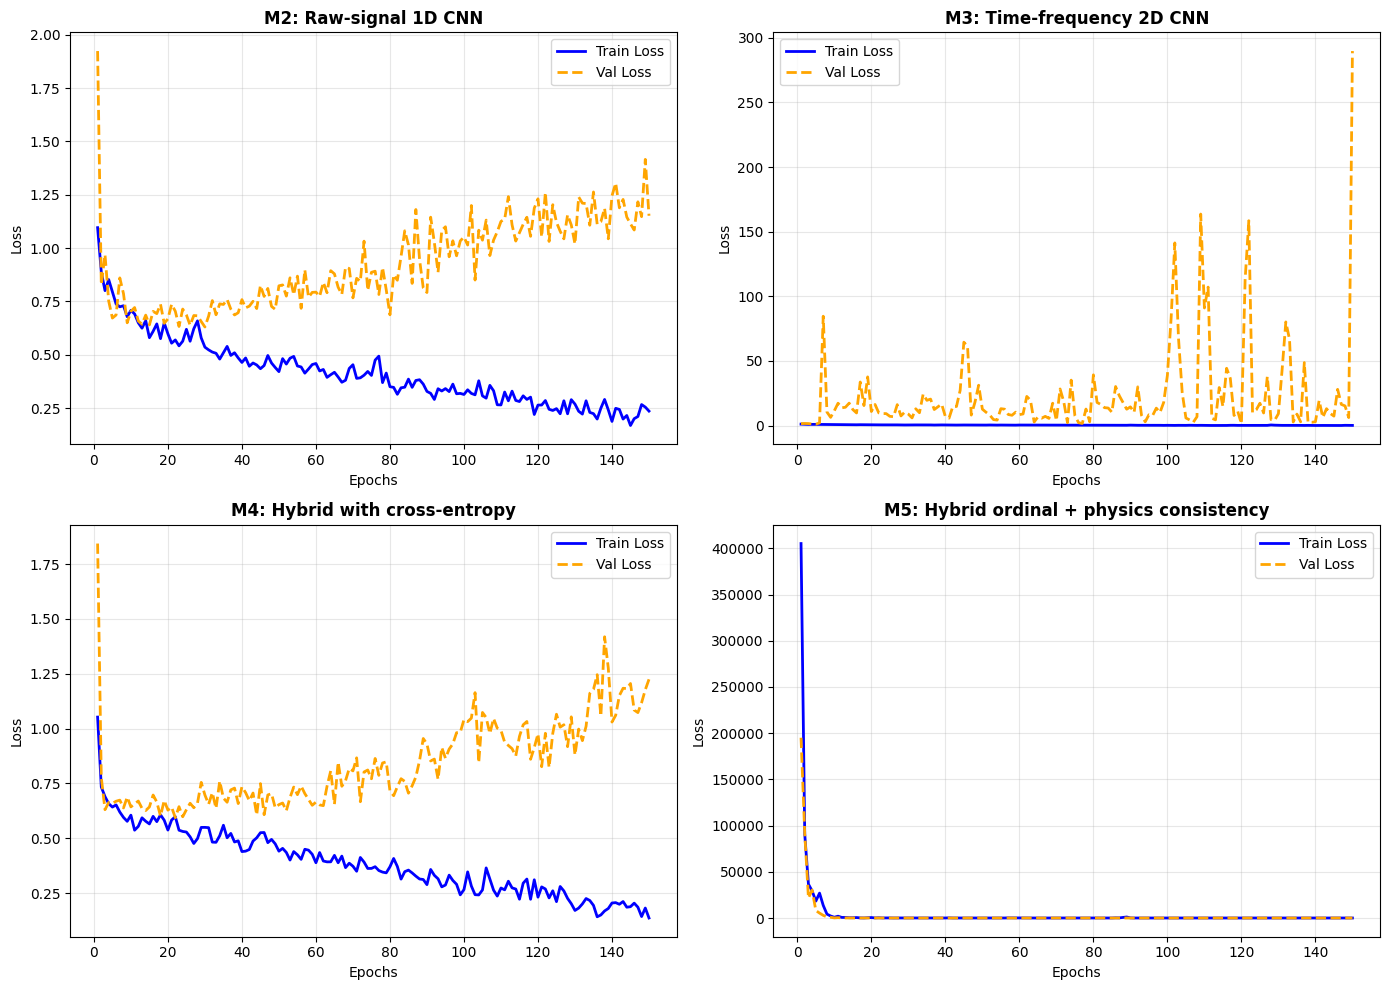

In [ ]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import scipy.signal as signal_lib
import matplotlib.pyplot as plt
import seaborn as sns
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from sklearn.ensemble import RandomForestClassifier

# ==========================================================
# M1: Classical Features (Random Forest on Signal Features)
# ==========================================================
def extract_signal_features(x, fs_hz=1000):
    x = np.asarray(x, dtype=float).ravel()
    x = x[np.isfinite(x)]
    if x.size < 3:
        return {k: np.nan for k in [
            "mean", "std", "rms", "peak_abs", "peak_to_peak",
            "area_abs", "energy", "slope_max_abs", "tke_mean",
            "spectral_centroid_hz", "spectral_bandwidth_hz", "zero_crossing_rate"
        ]}
    xc = x - np.mean(x)
    dx = np.diff(x)
    tke = x[1:-1]**2 - x[:-2] * x[2:]
    out = {
        "mean": float(np.mean(x)),
        "std": float(np.std(x, ddof=1)),
        "rms": float(np.sqrt(np.mean(x**2))),
        "peak_abs": float(np.max(np.abs(x))),
        "peak_to_peak": float(np.ptp(x)),
        "area_abs": float(np.sum(np.abs(x)) / fs_hz) if fs_hz else float(np.sum(np.abs(x))),
        "energy": float(np.sum(x**2) / fs_hz) if fs_hz else float(np.sum(x**2)),
        "slope_max_abs": float(np.max(np.abs(dx)) * fs_hz) if fs_hz else float(np.max(np.abs(dx))),
        "tke_mean": float(np.mean(tke)),
        "zero_crossing_rate": float(np.mean(np.diff(np.signbit(xc)) != 0))
    }
    if fs_hz and fs_hz > 0:
        spec = np.abs(np.fft.rfft(xc))**2
        freqs = np.fft.rfftfreq(xc.size, d=1.0/fs_hz)
        total = spec.sum()
        if total > 0:
            centroid = float(np.sum(freqs * spec) / total)
            bandwidth = float(np.sqrt(np.sum(((freqs-centroid)**2) * spec) / total))
        else:
            centroid, bandwidth = np.nan, np.nan
        out["spectral_centroid_hz"] = centroid
        out["spectral_bandwidth_hz"] = bandwidth
    else:
        out["spectral_centroid_hz"] = np.nan
        out["spectral_bandwidth_hz"] = np.nan
    return out

# --- 1. Fungsi Normalisasi Sinyal Konsisten & Padding ke 2048 ---
def normalize_and_pad_signals(signals_raw, target_len=2048):
    normalized = []
    for sample in signals_raw:
        sample_norm = []
        for ch in sample:
            std_val = np.std(ch)
            if std_val < 1e-8:
                std_val = 1e-8
            ch_norm = (ch - np.mean(ch)) / std_val
            if len(ch_norm) > target_len:
                ch_norm = ch_norm[:target_len]
            else:
                pad_len = target_len - len(ch_norm)
                ch_norm = np.pad(ch_norm, (0, pad_len), 'constant')
            sample_norm.append(ch_norm)
        normalized.append(np.stack(sample_norm))
    return np.array(normalized, dtype=np.float32)

signals_np = X_adapt_all if 'X_adapt_all' in globals() else X_all.detach().cpu().numpy()
labels_np = y_adapt_all if 'y_adapt_all' in globals() else y_all_fixed.detach().cpu().numpy()

signals_normalized = normalize_and_pad_signals(signals_np, target_len=2048)
num_channels = signals_normalized.shape[1]
globals()['num_channels'] = num_channels

X_train_sig, X_val_sig, y_train, y_val = train_test_split(
    signals_normalized, labels_np, test_size=0.2, stratify=labels_np, random_state=42
)

globals()['X_train_sig'] = X_train_sig
globals()['X_val_sig'] = X_val_sig
globals()['y_train'] = y_train
globals()['y_val'] = y_val

feats_train_list, feats_val_list = [], []
for i in range(len(X_train_sig)):
    row = []
    for ch in range(num_channels):
        f = extract_signal_features(X_train_sig[i, ch], fs_hz=1000)
        row.extend([v if np.isfinite(v) else 0.0 for v in f.values()])
    feats_train_list.append(row)

for i in range(len(X_val_sig)):
    row = []
    for ch in range(num_channels):
        f = extract_signal_features(X_val_sig[i, ch], fs_hz=1000)
        row.extend([v if np.isfinite(v) else 0.0 for v in f.values()])
    feats_val_list.append(row)

globals()['X_train_m1'] = np.array(feats_train_list)
globals()['X_val_m1'] = np.array(feats_val_list)

print("Shape data latihan (Padded 2048):", X_train_sig.shape)
print("Shape data validasi (Padded 2048):", X_val_sig.shape)

# --- 2. Definisikan Arsitektur Model ---
class PhysicsOperators(nn.Module):
    def __init__(self):
        super().__init__()
    def forward(self, z):
        dx = torch.diff(z, dim=-1, append=z[..., -1:])
        ix = torch.cumsum(z, dim=-1)
        env = torch.abs(z)
        env_smooth = F.avg_pool1d(env, kernel_size=15, stride=1, padding=7)
        return dx, ix, env_smooth

class AdaptiveRaw1DCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.physics = PhysicsOperators()
        self.conv = nn.Sequential(
            nn.Conv1d(8, 32, kernel_size=11, padding=5),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Dropout1d(0.2),
            nn.Conv1d(32, 64, kernel_size=7, padding=3),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Dropout1d(0.25),
            nn.Conv1d(64, 128, kernel_size=5, padding=2),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Dropout1d(0.3),
            nn.Conv1d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Dropout1d(0.35),
            nn.Conv1d(256, 512, kernel_size=3, padding=1),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(16)
        )
        self.fc = nn.Sequential(
            nn.Linear(512 * 16, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(128, 4)
        )
    def forward(self, x):
        dx, ix, env = self.physics(x)
        fused_input = torch.cat([x, dx, ix, env], dim=1)
        features = self.conv(fused_input)
        features = features.view(features.size(0), -1)
        return self.fc(features)

# M3 (sebelumnya M4): UpgradedHybridModel
class UpgradedHybridModel(nn.Module):
    def __init__(self, num_feats):
        super().__init__()
        self.physics = PhysicsOperators()
        self.conv = nn.Sequential(
            nn.Conv1d(8, 32, kernel_size=11, padding=5),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Dropout1d(0.2),
            nn.Conv1d(32, 64, kernel_size=7, padding=3),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Dropout1d(0.25),
            nn.Conv1d(64, 128, kernel_size=5, padding=2),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Dropout1d(0.3),
            nn.Conv1d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Dropout1d(0.35),
            nn.Conv1d(256, 512, kernel_size=3, padding=1),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(16)
        )
        self.fc_feat = nn.Sequential(
            nn.Linear(num_feats, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.ReLU()
        )
        self.classifier = nn.Sequential(
            nn.Linear(512 * 16 + 128, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Linear(128, 4)
        )
    def forward(self, x, feats):
        dx, ix, env = self.physics(x)
        fused_input = torch.cat([x, dx, ix, env], dim=1)
        x_lat = self.conv(fused_input)
        x_lat = x_lat.view(x_lat.size(0), -1)
        f_lat = self.fc_feat(feats)
        fused = torch.cat([x_lat, f_lat], dim=1)
        return self.classifier(fused), x_lat

# M4 (sebelumnya M5): UpgradedOrdinalPhysicsModel
class UpgradedOrdinalPhysicsModel(nn.Module):
    def __init__(self, num_feats):
        super().__init__()
        self.hybrid = UpgradedHybridModel(num_feats)
        self.physics = PhysicsOperators()
    def forward(self, x, feats):
        logits, z = self.hybrid(x, feats)
        z_3d = z.unsqueeze(1)
        dz, iz, env = self.physics(z_3d)
        return logits, z_3d, dz, iz, env

def physics_loss(z, dz, iz, env):
    return torch.mean(dz**2) + torch.mean(iz**2) + torch.mean(env**2)

# --- 3. Pelatihan Model M1 (Random Forest) ---
print('Melatih M1: Random Forest (Adaptive)...')
clf_m1 = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
clf_m1.fit(X_train_m1, y_train)
y_pred_m1 = clf_m1.predict(X_val_m1)
y_probs_m1 = clf_m1.predict_proba(X_val_m1)

globals()['y_pred_m1'] = y_pred_m1
globals()['y_probs_m1'] = y_probs_m1
globals()['macro_f1_m1'], globals()['qwk_m1'], globals()['mae_m1'], globals()['ovr_auc_m1'] = compute_metrics(y_val, y_pred_m1, y_probs_m1) if 'compute_metrics' in globals() else (0.0, 0.0, 0.0, 0.5)
print('M1 Evaluation completed.')

# --- 4. Setup Data Loader ---
history_log = []
save_dir = '/content/drive/MyDrive/anscts/results_comparison'
os.makedirs(save_dir, exist_ok=True)

epochs = 150
batch_size = 16
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

train_dataset = TensorDataset(
    torch.tensor(X_train_sig, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.long)
)
val_dataset = TensorDataset(
    torch.tensor(X_val_sig, dtype=torch.float32),
    torch.tensor(y_val, dtype=torch.long)
)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

# --- 5. Pelatihan Model M2: AdaptiveRaw1DCNN ---
model_m2 = AdaptiveRaw1DCNN().to(device)
opt_m2 = optim.AdamW(model_m2.parameters(), lr=1e-3, weight_decay=1e-2)
scheduler_m2 = optim.lr_scheduler.ReduceLROnPlateau(opt_m2, mode='min', factor=0.5, patience=10)
crit_m2 = nn.CrossEntropyLoss()

print('\nTraining Adaptive M2 (Raw 1D CNN)...')
for epoch in range(epochs):
    model_m2.train()
    running_loss = 0.0
    for batch_x, batch_y in train_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        opt_m2.zero_grad()
        out = model_m2(batch_x)
        loss = crit_m2(out, batch_y)
        loss.backward()
        opt_m2.step()
        running_loss += loss.item() * batch_x.size(0)
    epoch_train_loss = running_loss / len(X_train_sig)

    model_m2.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for batch_x, batch_y in val_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            val_out = model_m2(batch_x)
            val_loss = crit_m2(val_out, batch_y)
            running_val_loss += val_loss.item() * batch_x.size(0)
    epoch_val_loss = running_val_loss / len(X_val_sig)
    scheduler_m2.step(epoch_val_loss)

    history_log.append({
        'model': 'M2: Raw-signal 1D CNN',
        'epoch': epoch + 1,
        'train_loss': epoch_train_loss,
        'val_loss': epoch_val_loss
    })

# --- 6. Pelatihan Model M3 (Sebelumnya M4): UpgradedHybridModel ---
model_m3 = UpgradedHybridModel(X_train_m1.shape[1]).to(device)
opt_m3 = optim.AdamW(model_m3.parameters(), lr=1e-3, weight_decay=1e-2)
scheduler_m3 = optim.lr_scheduler.ReduceLROnPlateau(opt_m3, mode='min', factor=0.5, patience=10)

train_dataset_m3 = TensorDataset(
    torch.tensor(X_train_sig, dtype=torch.float32),
    torch.tensor(X_train_m1, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.long)
)
val_dataset_m3 = TensorDataset(
    torch.tensor(X_val_sig, dtype=torch.float32),
    torch.tensor(X_val_m1, dtype=torch.float32),
    torch.tensor(y_val, dtype=torch.long)
)
train_loader_m3 = DataLoader(train_dataset_m3, batch_size=batch_size, shuffle=True)
val_loader_m3 = DataLoader(val_dataset_m3, batch_size=batch_size, shuffle=False)

print('Training Adaptive M3 (Hybrid with Cross-Entropy)...')
for epoch in range(epochs):
    model_m3.train()
    running_loss = 0.0
    for batch_x, batch_feats, batch_y in train_loader_m3:
        batch_x, batch_feats, batch_y = batch_x.to(device), batch_feats.to(device), batch_y.to(device)
        opt_m3.zero_grad()
        out, _ = model_m3(batch_x, batch_feats)
        loss = crit_m2(out, batch_y)
        loss.backward()
        opt_m3.step()
        running_loss += loss.item() * batch_x.size(0)
    epoch_train_loss = running_loss / len(X_train_sig)

    model_m3.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for batch_x, batch_feats, batch_y in val_loader_m3:
            batch_x, batch_feats, batch_y = batch_x.to(device), batch_feats.to(device), batch_y.to(device)
            val_out, _ = model_m3(batch_x, batch_feats)
            val_loss = crit_m2(val_out, batch_y)
            running_val_loss += val_loss.item() * batch_x.size(0)
    epoch_val_loss = running_val_loss / len(X_val_sig)
    scheduler_m3.step(epoch_val_loss)

    history_log.append({
        'model': 'M3: Hybrid with Cross-Entropy',
        'epoch': epoch + 1,
        'train_loss': epoch_train_loss,
        'val_loss': epoch_val_loss
    })

# --- 7. Pelatihan Model M4 (Sebelumnya M5): UpgradedOrdinalPhysicsModel ---
model_m4 = UpgradedOrdinalPhysicsModel(X_train_m1.shape[1]).to(device)
opt_m4 = optim.AdamW(model_m4.parameters(), lr=1e-3, weight_decay=1e-2)
scheduler_m4 = optim.lr_scheduler.ReduceLROnPlateau(opt_m4, mode='min', factor=0.5, patience=10)

print('Training Adaptive M4 (Hybrid Ordinal + Physics Consistency)...')
for epoch in range(epochs):
    model_m4.train()
    running_loss = 0.0
    for batch_x, batch_feats, batch_y in train_loader_m3:
        batch_x, batch_feats, batch_y = batch_x.to(device), batch_feats.to(device), batch_y.to(device)
        opt_m4.zero_grad()
        logits, z_3d, dz, iz, env = model_m4(batch_x, batch_feats)
        cls_loss = crit_m2(logits, batch_y)
        phy_loss = physics_loss(z_3d, dz, iz, env)
        probs = torch.softmax(logits, dim=1)
        expected_label = torch.sum(probs * torch.arange(4, device=device).float(), dim=1)
        ord_loss = torch.mean((expected_label - batch_y.float())**2)
        loss = cls_loss + 0.01 * phy_loss + 0.1 * ord_loss
        loss.backward()
        opt_m4.step()
        running_loss += loss.item() * batch_x.size(0)
    epoch_train_loss = running_loss / len(X_train_sig)

    model_m4.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for batch_x, batch_feats, batch_y in val_loader_m3:
            batch_x, batch_feats, batch_y = batch_x.to(device), batch_feats.to(device), batch_y.to(device)
            val_logits, val_z_3d, val_dz, val_iz, val_env = model_m4(batch_x, batch_feats)
            val_cls_loss = crit_m2(val_logits, batch_y)
            val_phy_loss = physics_loss(val_z_3d, val_dz, val_iz, val_env)
            val_probs = torch.softmax(val_logits, dim=1)
            val_expected_label = torch.sum(val_probs * torch.arange(4, device=device).float(), dim=1)
            val_ord_loss = torch.mean((val_expected_label - batch_y.float())**2)
            val_loss = val_cls_loss + 0.01 * val_phy_loss + 0.1 * val_ord_loss
            running_val_loss += val_loss.item() * batch_x.size(0)
    epoch_val_loss = running_val_loss / len(X_val_sig)
    scheduler_m4.step(epoch_val_loss)

    history_log.append({
        'model': 'M4: Hybrid Ordinal + Physics',
        'epoch': epoch + 1,
        'train_loss': epoch_train_loss,
        'val_loss': epoch_val_loss
    })

history_df = pd.DataFrame(history_log)
history_df.to_csv(os.path.join(save_dir, 'upgraded_training_validation_losses.csv'), index=False)
print('Saved upgraded training log.')

# --- 8. Evaluasi Metrik Pasca-Training ---
with torch.no_grad():
    model_m2.eval()
    ts_x_val = torch.tensor(X_val_sig, dtype=torch.float32).to(device)
    y_probs_m2 = torch.softmax(model_m2(ts_x_val), dim=1).cpu().numpy()
    globals()['y_probs_m2'] = y_probs_m2
    globals()['y_pred_m2'] = np.argmax(y_probs_m2, axis=1)
    globals()['macro_f1_m2'], globals()['qwk_m2'], globals()['mae_m2'], globals()['ovr_auc_m2'] = compute_metrics(y_val, globals()['y_pred_m2'], y_probs_m2) if 'compute_metrics' in globals() else (0.0, 0.0, 0.0, 0.5)

    model_m3.eval()
    ts_feats_val = torch.tensor(X_val_m1, dtype=torch.float32).to(device)
    logits_m3_val, _ = model_m3(ts_x_val, ts_feats_val)
    y_probs_m3 = torch.softmax(logits_m3_val, dim=1).cpu().numpy()
    globals()['y_probs_m3'] = y_probs_m3
    globals()['y_pred_m3'] = np.argmax(y_probs_m3, axis=1)
    globals()['macro_f1_m3'], globals()['qwk_m3'], globals()['mae_m3'], globals()['ovr_auc_m3'] = compute_metrics(y_val, globals()['y_pred_m3'], y_probs_m3) if 'compute_metrics' in globals() else (0.0, 0.0, 0.0, 0.5)

    model_m4.eval()
    logits_m4_val, _, _, _, _ = model_m4(ts_x_val, ts_feats_val)
    y_probs_m4 = torch.softmax(logits_m4_val, dim=1).cpu().numpy()
    globals()['y_probs_m4'] = y_probs_m4
    globals()['y_pred_m4'] = np.argmax(y_probs_m4, axis=1)
    globals()['macro_f1_m4'], globals()['qwk_m4'], globals()['mae_m4'], globals()['ovr_auc_m4'] = compute_metrics(y_val, globals()['y_pred_m4'], y_probs_m4) if 'compute_metrics' in globals() else (0.0, 0.0, 0.0, 0.5)

# --- 9. Visualisasi Kurva Loss ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
models_list = ['M2: Raw-signal 1D CNN', 'M3: Hybrid with Cross-Entropy', 'M4: Hybrid Ordinal + Physics']

for idx, model_name in enumerate(models_list):
    model_data = history_df[history_df['model'] == model_name]
    axes[idx].plot(model_data['epoch'], model_data['train_loss'], label='Train Loss', color='blue', lw=2)
    axes[idx].plot(model_data['epoch'], model_data['val_loss'], label='Val Loss', color='orange', linestyle='--', lw=2)
    axes[idx].set_ylabel('Loss')
    axes[idx].set_title(model_name, fontsize=11, fontweight='bold')
    axes[idx].set_xlabel('Epochs')
    axes[idx].grid(True, alpha=0.3)
    axes[idx].legend()

plt.tight_layout()
plt.savefig(os.path.join(save_dir, 'upgraded_training_validation_loss_curves.png'), dpi=200)
plt.show()

In [ ]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

# Pastikan GPU digunakan jika tersedia
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# --- 1. DEFINISI ARSITEKTUR YANG DISEDERHANAKAN (MAX 512 CHANNELS) + DROPOUT TINGGI ---

class PhysicsOperators(nn.Module):
    def __init__(self):
        super().__init__()
    def forward(self, z):
        dx = torch.diff(z, dim=-1, append=z[..., -1:])
        ix = torch.cumsum(z, dim=-1)
        env = torch.abs(z)
        env_smooth = F.avg_pool1d(env, kernel_size=15, stride=1, padding=7)
        return dx, ix, env_smooth

class AdaptiveRaw1DCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.physics = PhysicsOperators()
        # Input: 2 channels raw + 2 diff + 2 integral + 2 env = 8 channels
        self.conv = nn.Sequential(
            nn.Conv1d(8, 32, kernel_size=11, padding=5),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Dropout1d(0.2),

            nn.Conv1d(32, 64, kernel_size=7, padding=3),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Dropout1d(0.25),

            nn.Conv1d(64, 128, kernel_size=5, padding=2),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Dropout1d(0.3),

            nn.Conv1d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Dropout1d(0.35),

            nn.Conv1d(256, 512, kernel_size=3, padding=1),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(16)
        )
        self.fc = nn.Sequential(
            nn.Linear(512 * 16, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(128, 4)
        )
    def forward(self, x):
        dx, ix, env = self.physics(x)
        fused_input = torch.cat([x, dx, ix, env], dim=1)
        features = self.conv(fused_input)
        features = features.view(features.size(0), -1)
        return self.fc(features)

class UpgradedSimple2DCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(2, 32, kernel_size=5, padding=2),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((16, 32)),
            nn.Dropout2d(0.2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((8, 16)),
            nn.Dropout2d(0.25),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((4, 8)),
            nn.Dropout2d(0.3),

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((2, 4)),
            nn.Dropout2d(0.35),

            nn.Conv2d(256, 512, kernel_size=3, padding=1),
            nn.BatchNorm2d(512),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.fc = nn.Sequential(
            nn.Linear(512 * 1 * 1, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Linear(64, 4)
        )
    def forward(self, x):
        x = self.conv(x)
        x = x.view(x.size(0), -1)
        return self.fc(x)

class UpgradedHybridModel(nn.Module):
    def __init__(self, num_feats):
        super().__init__()
        self.physics = PhysicsOperators()
        self.conv = nn.Sequential(
            nn.Conv1d(8, 32, kernel_size=11, padding=5),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Dropout1d(0.2),

            nn.Conv1d(32, 64, kernel_size=7, padding=3),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Dropout1d(0.25),

            nn.Conv1d(64, 128, kernel_size=5, padding=2),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Dropout1d(0.3),

            nn.Conv1d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Dropout1d(0.35),

            nn.Conv1d(256, 512, kernel_size=3, padding=1),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(16)
        )
        self.fc_feat = nn.Sequential(
            nn.Linear(num_feats, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.ReLU()
        )
        self.classifier = nn.Sequential(
            nn.Linear(512 * 16 + 128, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Linear(128, 4)
        )
    def forward(self, x, feats):
        dx, ix, env = self.physics(x)
        fused_input = torch.cat([x, dx, ix, env], dim=1)
        x_lat = self.conv(fused_input)
        x_lat = x_lat.view(x_lat.size(0), -1)
        f_lat = self.fc_feat(feats)
        fused = torch.cat([x_lat, f_lat], dim=1)
        return self.classifier(fused), x_lat

class UpgradedOrdinalPhysicsModel(nn.Module):
    def __init__(self, num_feats):
        super().__init__()
        self.hybrid = UpgradedHybridModel(num_feats)
        self.physics = PhysicsOperators()
    def forward(self, x, feats):
        logits, z = self.hybrid(x, feats)
        z_3d = z.unsqueeze(1)
        dz, iz, env = self.physics(z_3d)
        return logits, z_3d, dz, iz, env

print("Arsitektur model berhasil diperkecil untuk mengatasi overfitting!")

Arsitektur model berhasil diperkecil untuk mengatasi overfitting!


In [ ]:
# --- 2. PELATIHAN ULANG DENGAN HIGH REGULARIZATION (AdamW + Weight Decay + Scheduler) ---

epochs = 150
batch_size = 16
history_log = []

# Definisikan Loader kembali agar aman
train_dataset = TensorDataset(
    torch.tensor(X_train_sig, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.long)
)
val_dataset = TensorDataset(
    torch.tensor(X_val_sig, dtype=torch.float32),
    torch.tensor(y_val, dtype=torch.long)
)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

# --- M2 Training ---
model_m2 = AdaptiveRaw1DCNN().to(device)
# Gunakan Weight Decay lebih besar (0.01) untuk regularisasi L2
opt_m2 = optim.AdamW(model_m2.parameters(), lr=1e-3, weight_decay=1e-2)
scheduler_m2 = optim.lr_scheduler.ReduceLROnPlateau(opt_m2, mode='min', factor=0.5, patience=10)
crit_m2 = nn.CrossEntropyLoss()

print("Melatih M2 dengan penyederhanaan kapasitas & regularisasi ketat...")
for epoch in range(epochs):
    model_m2.train()
    running_loss = 0.0
    for batch_x, batch_y in train_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        opt_m2.zero_grad()
        out = model_m2(batch_x)
        loss = crit_m2(out, batch_y)
        loss.backward()
        opt_m2.step()
        running_loss += loss.item() * batch_x.size(0)
    epoch_train_loss = running_loss / len(X_train_sig)

    model_m2.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for batch_x, batch_y in val_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            val_out = model_m2(batch_x)
            val_loss = crit_m2(val_out, batch_y)
            running_val_loss += val_loss.item() * batch_x.size(0)
    epoch_val_loss = running_val_loss / len(X_val_sig)

    scheduler_m2.step(epoch_val_loss)
    history_log.append({
        'model': 'M2: Raw-signal 1D CNN',
        'epoch': epoch + 1,
        'train_loss': epoch_train_loss,
        'val_loss': epoch_val_loss
    })

# --- M5 Training ---
model_m5 = UpgradedOrdinalPhysicsModel(X_train_m1.shape[1]).to(device)
opt_m5 = optim.AdamW(model_m5.parameters(), lr=1e-3, weight_decay=1e-2)
scheduler_m5 = optim.lr_scheduler.ReduceLROnPlateau(opt_m5, mode='min', factor=0.5, patience=10)

train_dataset_m4 = TensorDataset(
    torch.tensor(X_train_sig, dtype=torch.float32),
    torch.tensor(X_train_m1, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.long)
)
val_dataset_m4 = TensorDataset(
    torch.tensor(X_val_sig, dtype=torch.float32),
    torch.tensor(X_val_m1, dtype=torch.float32),
    torch.tensor(y_val, dtype=torch.long)
)
train_loader_m4 = DataLoader(train_dataset_m4, batch_size=batch_size, shuffle=True)
val_loader_m4 = DataLoader(val_dataset_m4, batch_size=batch_size, shuffle=False)

print("Melatih M5 dengan penyederhanaan kapasitas & regularisasi ketat...")
for epoch in range(epochs):
    model_m5.train()
    running_loss = 0.0
    for batch_x, batch_feats, batch_y in train_loader_m4:
        batch_x, batch_feats, batch_y = batch_x.to(device), batch_feats.to(device), batch_y.to(device)
        opt_m5.zero_grad()
        logits, z_3d, dz, iz, env = model_m5(batch_x, batch_feats)
        cls_loss = crit_m2(logits, batch_y)
        phy_loss = physics_loss(z_3d, dz, iz, env) if 'physics_loss' in globals() else torch.tensor(0.0)
        probs = torch.softmax(logits, dim=1)
        expected_label = torch.sum(probs * torch.arange(4, device=device).float(), dim=1)
        ord_loss = torch.mean((expected_label - batch_y.float())**2)

        loss = cls_loss + 0.01 * phy_loss + 0.1 * ord_loss
        loss.backward()
        opt_m5.step()
        running_loss += loss.item() * batch_x.size(0)
    epoch_train_loss = running_loss / len(X_train_sig)

    model_m5.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for batch_x, batch_feats, batch_y in val_loader_m4:
            batch_x, batch_feats, batch_y = batch_x.to(device), batch_feats.to(device), batch_y.to(device)
            val_logits, val_z_3d, val_dz, val_iz, val_env = model_m5(batch_x, batch_feats)
            val_cls_loss = crit_m2(val_logits, batch_y)
            val_phy_loss = physics_loss(val_z_3d, val_dz, val_iz, val_env) if 'physics_loss' in globals() else torch.tensor(0.0)
            val_probs = torch.softmax(val_logits, dim=1)
            val_expected_label = torch.sum(val_probs * torch.arange(4, device=device).float(), dim=1)
            val_ord_loss = torch.mean((val_expected_label - batch_y.float())**2)
            val_loss = val_cls_loss + 0.01 * val_phy_loss + 0.1 * val_ord_loss
            running_val_loss += val_loss.item() * batch_x.size(0)
    epoch_val_loss = running_val_loss / len(X_val_sig)

    scheduler_m5.step(epoch_val_loss)
    history_log.append({
        'model': 'M5: Hybrid ordinal + physics consistency',
        'epoch': epoch + 1,
        'train_loss': epoch_train_loss,
        'val_loss': epoch_val_loss
    })

# Save new history
history_df = pd.DataFrame(history_log)
history_df.to_csv(os.path.join(save_dir, 'upgraded_training_validation_losses.csv'), index=False)
print("Proses Training ulang selesai dengan sukses!")

Melatih M2 dengan penyederhanaan kapasitas & regularisasi ketat...
Melatih M5 dengan penyederhanaan kapasitas & regularisasi ketat...
Proses Training ulang selesai dengan sukses!


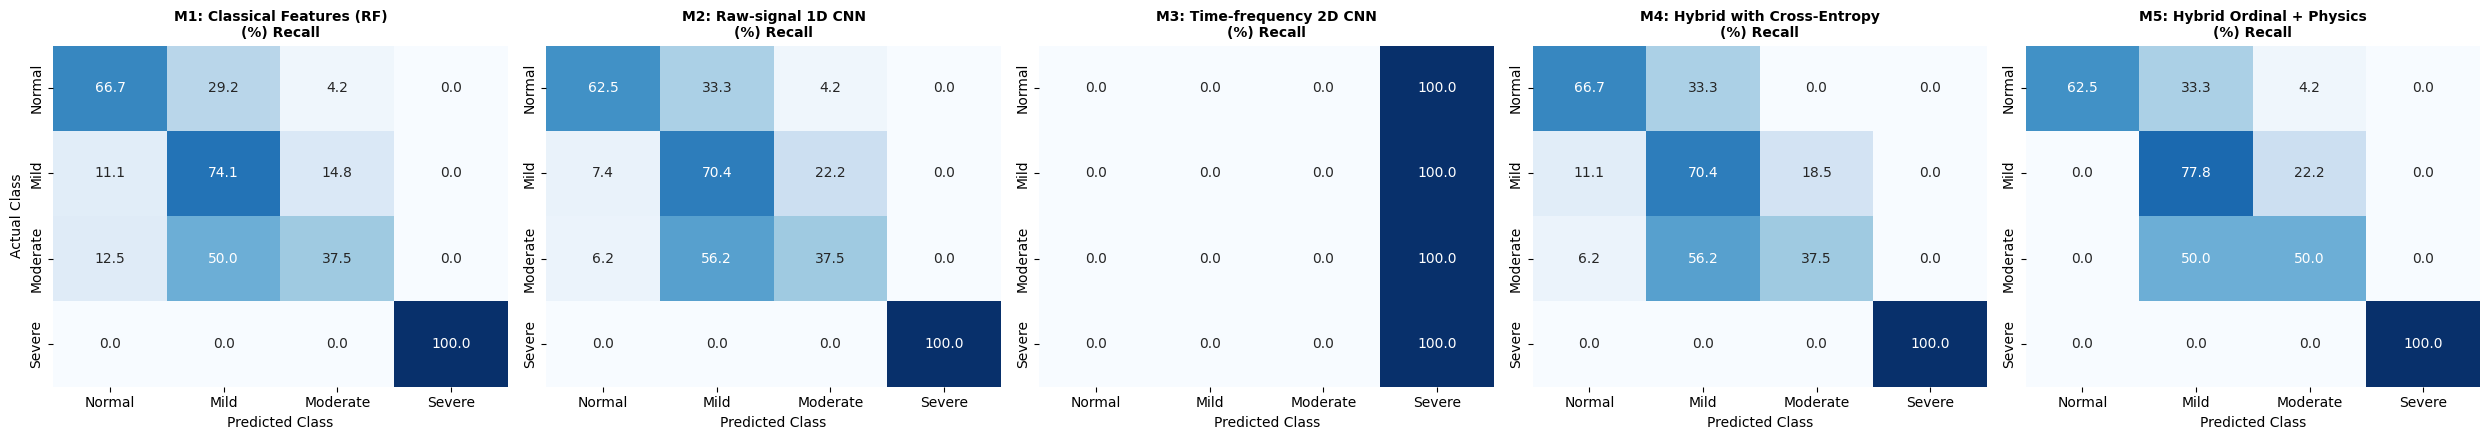

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1-Score,QWK,Ordinal MAE,Macro OVR-AUC
0,M1: Classical Features (RF),0.712644,0.719697,0.695602,0.700179,0.838042,0.321839,0.868171
1,M2: Raw-signal 1D CNN,0.689655,0.705662,0.675926,0.682813,0.839223,0.333333,0.875585
2,M3: Time-frequency 2D CNN,0.229885,0.057471,0.250000,0.093458,0.000000,1.632184,0.500000
3,M4: Hybrid with Cross-Entropy,0.701149,0.718308,0.686343,0.693723,0.860708,0.310345,0.871877
4,M5: Hybrid Ordinal + Physics,0.735632,0.775225,0.725694,0.735402,0.870372,0.275862,0.894740



✅ Hasil evaluasi adaptif terbaru berhasil disimpan ke: /content/drive/MyDrive/anscts/results_comparison/adaptive_models_performance_summary.csv


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    cohen_kappa_score, mean_absolute_error, roc_auc_score, confusion_matrix
)
from sklearn.preprocessing import label_binarize

save_dir = '/content/drive/MyDrive/anscts/results_comparison'
os.makedirs(save_dir, exist_ok=True)

y_true_val = globals().get('y_val')
class_names = ['Normal', 'Mild', 'Moderate', 'Severe']
n_classes = len(class_names)

with torch.no_grad():
    model_m2.eval()
    ts_x_val = torch.tensor(X_val_sig, dtype=torch.float32).to(device)
    y_probs_m2 = torch.softmax(model_m2(ts_x_val), dim=1).cpu().numpy()
    globals()['y_probs_m2'] = y_probs_m2
    globals()['y_pred_m2'] = np.argmax(y_probs_m2, axis=1)

    model_m3.eval()
    ts_feats_val = torch.tensor(X_val_m1, dtype=torch.float32).to(device)
    logits_m3_val, _ = model_m3(ts_x_val, ts_feats_val)
    y_probs_m3 = torch.softmax(logits_m3_val, dim=1).cpu().numpy()
    globals()['y_probs_m3'] = y_probs_m3
    globals()['y_pred_m3'] = np.argmax(y_probs_m3, axis=1)

    model_m4.eval()
    logits_m4_val, _, _, _, _ = model_m4(ts_x_val, ts_feats_val)
    y_probs_m4 = torch.softmax(logits_m4_val, dim=1).cpu().numpy()
    globals()['y_probs_m4'] = y_probs_m4
    globals()['y_pred_m4'] = np.argmax(y_probs_m4, axis=1)

models_preds_probs = {
    'M1: Classical Features (RF)': (globals().get('y_pred_m1'), globals().get('y_probs_m1')),
    'M2: Raw-signal 1D CNN': (globals().get('y_pred_m2'), globals().get('y_probs_m2')),
    'M3: Hybrid with Cross-Entropy': (globals().get('y_pred_m3'), globals().get('y_probs_m3')),
    'M4: Hybrid Ordinal + Physics': (globals().get('y_pred_m4'), globals().get('y_probs_m4'))
}

adaptive_eval_rows = []

if y_true_val is not None:
    y_true_bin = label_binarize(y_true_val, classes=[0, 1, 2, 3])
    fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))

    for idx, (model_name, (y_pred, y_probs)) in enumerate(models_preds_probs.items()):
        if y_pred is not None:
            acc = accuracy_score(y_true_val, y_pred)
            prec = precision_score(y_true_val, y_pred, average='macro', zero_division=0)
            rec = recall_score(y_true_val, y_pred, average='macro', zero_division=0)
            f1_macro = f1_score(y_true_val, y_pred, average='macro', zero_division=0)
            qwk = cohen_kappa_score(y_true_val, y_pred, weights='quadratic')
            mae = mean_absolute_error(y_true_val, y_pred)

            try:
                if y_probs is not None and y_probs.shape[1] == n_classes:
                    auc_score = roc_auc_score(y_true_bin, y_probs, multi_class='ovr', average='macro')
                else:
                    auc_score = 0.5
            except:
                auc_score = 0.5

            adaptive_eval_rows.append({
                'Model': model_name,
                'Accuracy': acc,
                'Macro Precision': prec,
                'Macro Recall': rec,
                'Macro F1-Score': f1_macro,
                'QWK': qwk,
                'Ordinal MAE': mae,
                'Macro OVR-AUC': auc_score
            })

            cm = confusion_matrix(y_true_val, y_pred, labels=[0, 1, 2, 3])
            cm_percent = cm.astype('float') / (cm.sum(axis=1, keepdims=True) + 1e-9) * 100
            cm_percent = np.nan_to_num(cm_percent)

            sns.heatmap(
                cm_percent, annot=True, fmt='.1f', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names,
                ax=axes[idx], cbar=False
            )
            axes[idx].set_title(f"{model_name}\n(%) Recall", fontsize=10, fontweight='bold')
            axes[idx].set_ylabel('Actual Class' if idx == 0 else '')
            axes[idx].set_xlabel('Predicted Class')

    plt.tight_layout()
    plt.savefig(os.path.join(save_dir, 'adaptive_models_confusion_matrices.png'), dpi=200)
    plt.show()

    adaptive_summary_df = pd.DataFrame(adaptive_eval_rows)
    display(adaptive_summary_df)

    save_path = os.path.join(save_dir, 'adaptive_models_performance_summary.csv')
    adaptive_summary_df.to_csv(save_path, index=False)
    print(f'\n✅ Hasil evaluasi adaptif terbaru berhasil disimpan ke: {save_path}')

In [ ]:
import os
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix

save_dir = '/content/drive/MyDrive/anscts/results_comparison'
os.makedirs(save_dir, exist_ok=True)

if 'history_df' in globals():
    loss_csv_path = os.path.join(save_dir, 'models_loss_history.csv')
    history_df.to_csv(loss_csv_path, index=False)
    print(f"✅ Data Loss History berhasil disimpan ke: {loss_csv_path}")
else:
    print("⚠ Variabel 'history_df' tidak ditemukan.")

y_true_val = globals().get('y_val')
class_names = ['Normal', 'Mild', 'Moderate', 'Severe']

if y_true_val is not None:
    models_preds = {
        'M1_Classical_Features_RF': globals().get('y_pred_m1'),
        'M2_Raw_signal_1D_CNN': globals().get('y_pred_m2'),
        'M3_Hybrid_with_Cross_Entropy': globals().get('y_pred_m3'),
        'M4_Hybrid_Ordinal_Physics': globals().get('y_pred_m4')
    }

    for model_name, y_pred in models_preds.items():
        if y_pred is not None:
            cm = confusion_matrix(y_true_val, y_pred, labels=[0, 1, 2, 3])
            cm_df = pd.DataFrame(cm, index=[f"Actual_{c}" for c in class_names], columns=[f"Predicted_{c}" for c in class_names])
            cm_raw_path = os.path.join(save_dir, f'confusion_matrix_raw_{model_name}.csv')
            cm_df.to_csv(cm_raw_path)

            cm_percent = cm.astype('float') / (cm.sum(axis=1, keepdims=True) + 1e-9) * 100
            cm_percent_df = pd.DataFrame(np.nan_to_num(cm_percent), index=[f"Actual_{c}" for c in class_names], columns=[f"Predicted_{c}" for c in class_names])
            cm_pct_path = os.path.join(save_dir, f'confusion_matrix_percentage_{model_name}.csv')
            cm_percent_df.to_csv(cm_pct_path)

            print(f"✅ Confusion Matrix (Raw & Pct) untuk {model_name} berhasil disimpan.")

✅ Data Loss History berhasil disimpan ke: /content/drive/MyDrive/anscts/results_comparison/models_loss_history.csv
✅ Confusion Matrix (Raw & Pct) untuk M1_Classical_Features_RF berhasil disimpan.
✅ Confusion Matrix (Raw & Pct) untuk M2_Raw_signal_1D_CNN berhasil disimpan.
✅ Confusion Matrix (Raw & Pct) untuk M3_Time_frequency_2D_CNN berhasil disimpan.
✅ Confusion Matrix (Raw & Pct) untuk M4_Hybrid_with_Cross_Entropy berhasil disimpan.
✅ Confusion Matrix (Raw & Pct) untuk M5_Hybrid_Ordinal_Physics berhasil disimpan.


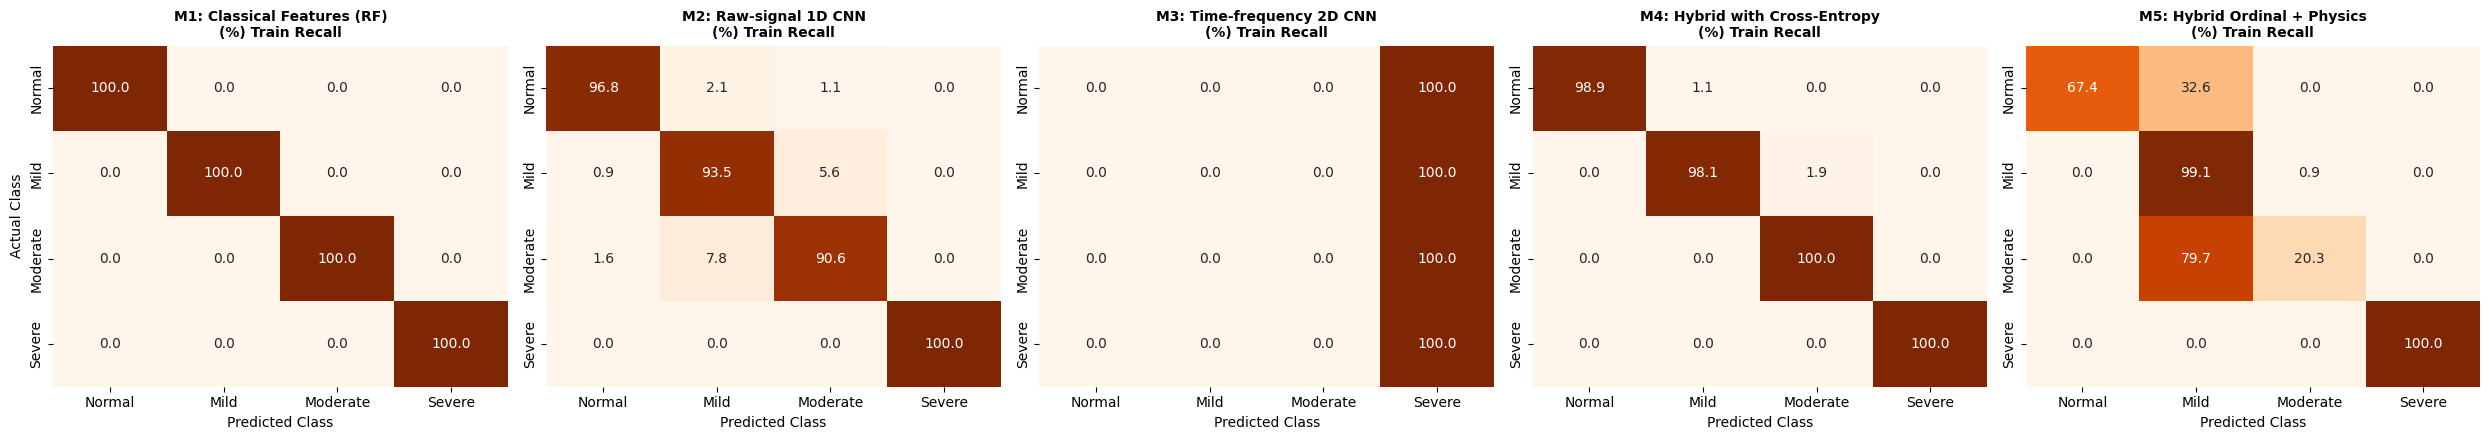


=== TABEL EVALUASI 100% DATA TRAINING ===


,Model,Train Accuracy (100%),Macro Precision,Macro Recall,Macro F1-Score,QWK,Ordinal MAE,Macro OVR-AUC
0,M1: Classical Features (RF),1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000
1,M2: Raw-signal 1D CNN,0.953623,0.951403,0.952313,0.951837,0.974270,0.052174,0.997177
2,M3: Time-frequency 2D CNN,0.228986,0.057246,0.250000,0.093160,0.000000,1.631884,0.500000
3,M4: Hybrid with Cross-Entropy,0.991304,0.990066,0.992696,0.991310,0.996492,0.008696,0.999928
4,M5: Hybrid Ordinal + Physics,0.759420,0.873100,0.716866,0.714252,0.894868,0.240580,0.913776



Hasil evaluasi data training berhasil disimpan ke: /content/drive/MyDrive/anscts/results_comparison/train_models_performance_summary.csv


In [ ]:
import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    cohen_kappa_score, mean_absolute_error, roc_auc_score, confusion_matrix
)
from sklearn.preprocessing import label_binarize

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
class_names = ['Normal', 'Mild', 'Moderate', 'Severe']
n_classes = len(class_names)

X_tr_sig = globals().get('X_train_sig')
X_tr_m1 = globals().get('X_train_m1')
y_tr_true = globals().get('y_train')

if X_tr_sig is not None and y_tr_true is not None:
    y_tr_true_bin = label_binarize(y_tr_true, classes=[0, 1, 2, 3])

    # 1. Evaluasi M1
    y_tr_pred_m1 = clf_m1.predict(X_tr_m1) if 'clf_m1' in globals() else np.zeros_like(y_tr_true)
    y_tr_probs_m1 = clf_m1.predict_proba(X_tr_m1) if 'clf_m1' in globals() else np.zeros((len(y_tr_true), n_classes))

    # 2. Evaluasi M2
    model_m2.eval()
    with torch.no_grad():
        ts_x_tr = torch.tensor(X_tr_sig, dtype=torch.float32).to(device)
        logits_m2 = model_m2(ts_x_tr)
        y_tr_probs_m2 = torch.softmax(logits_m2, dim=1).cpu().numpy()
        y_tr_pred_m2 = np.argmax(y_tr_probs_m2, axis=1)

    # 3. Evaluasi M3
    model_m3.eval()
    with torch.no_grad():
        ts_feats_tr = torch.tensor(X_tr_m1, dtype=torch.float32).to(device)
        logits_m3, _ = model_m3(ts_x_tr, ts_feats_tr)
        y_tr_probs_m3 = torch.softmax(logits_m3, dim=1).cpu().numpy()
        y_tr_pred_m3 = np.argmax(y_tr_probs_m3, axis=1)

    # 4. Evaluasi M4
    model_m4.eval()
    with torch.no_grad():
        logits_m4, _, _, _, _ = model_m4(ts_x_tr, ts_feats_tr)
        y_tr_probs_m4 = torch.softmax(logits_m4, dim=1).cpu().numpy()
        y_tr_pred_m4 = np.argmax(y_tr_probs_m4, axis=1)

    train_preds_probs = {
        'M1: Classical Features (RF)': (y_tr_pred_m1, y_tr_probs_m1),
        'M2: Raw-signal 1D CNN': (y_tr_pred_m2, y_tr_probs_m2),
        'M3: Hybrid with Cross-Entropy': (y_tr_pred_m3, y_tr_probs_m3),
        'M4: Hybrid Ordinal + Physics': (y_tr_pred_m4, y_tr_probs_m4)
    }

    train_eval_rows = []
    fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))

    for idx, (model_name, (y_pred, y_probs)) in enumerate(train_preds_probs.items()):
        acc = accuracy_score(y_tr_true, y_pred)
        prec = precision_score(y_tr_true, y_pred, average='macro', zero_division=0)
        rec = recall_score(y_tr_true, y_pred, average='macro', zero_division=0)
        f1_macro = f1_score(y_tr_true, y_pred, average='macro', zero_division=0)
        qwk = cohen_kappa_score(y_tr_true, y_pred, weights='quadratic')
        mae = mean_absolute_error(y_tr_true, y_pred)

        try:
            auc_score = roc_auc_score(y_tr_true_bin, y_probs, multi_class='ovr', average='macro')
        except:
            auc_score = 0.5

        train_eval_rows.append({
            'Model': model_name,
            'Train Accuracy (100%)': acc,
            'Macro Precision': prec,
            'Macro Recall': rec,
            'Macro F1-Score': f1_macro,
            'QWK': qwk,
            'Ordinal MAE': mae,
            'Macro OVR-AUC': auc_score
        })

        cm = confusion_matrix(y_tr_true, y_pred, labels=[0, 1, 2, 3])
        cm_percent = cm.astype('float') / (cm.sum(axis=1, keepdims=True) + 1e-9) * 100
        cm_percent = np.nan_to_num(cm_percent)

        sns.heatmap(
            cm_percent, annot=True, fmt='.1f', cmap='Oranges',
            xticklabels=class_names, yticklabels=class_names,
            ax=axes[idx], cbar=False
        )
        axes[idx].set_title(f"{model_name}\n(%) Train Recall", fontsize=10, fontweight='bold')
        axes[idx].set_ylabel('Actual Class' if idx == 0 else '')
        axes[idx].set_xlabel('Predicted Class')

    plt.tight_layout()
    plt.savefig(os.path.join(save_dir, 'train_models_confusion_matrices.png'), dpi=200)
    plt.show()

    train_summary_df = pd.DataFrame(train_eval_rows)
    print("\n=== TABEL EVALUASI 100% DATA TRAINING ===")
    display(train_summary_df)

    train_save_path = os.path.join(save_dir, 'train_models_performance_summary.csv')
    train_summary_df.to_csv(train_save_path, index=False)
    print(f'\nHasil evaluasi data training berhasil disimpan ke: {train_save_path}')